<a href="https://colab.research.google.com/github/TheoBrascher/colabfold2_public/blob/main/AlphaFold2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://raw.githubusercontent.com/sokrypton/ColabFold/main/.github/ColabFold_Marv_Logo_Small.png" height="200" align="right" style="height:240px">

##ColabFold v1.6.3: AlphaFold2 using MMseqs2

Easy to use protein structure and complex prediction using [AlphaFold2](https://www.nature.com/articles/s41586-021-03819-2) and [Alphafold2-multimer](https://www.biorxiv.org/content/10.1101/2021.10.04.463034v1). Sequence alignments/templates are generated through [MMseqs2](mmseqs.com) and [HHsearch](https://github.com/soedinglab/hh-suite). For more details, see <a href="#Instructions">bottom</a> of the notebook, checkout the [ColabFold GitHub](https://github.com/sokrypton/ColabFold) and [Nature Protocols](https://www.nature.com/articles/s41596-024-01060-5).

Old versions: [v1.4](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.4.0/AlphaFold2.ipynb), [v1.5.1](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.5.1/AlphaFold2.ipynb), [v1.5.2](https://colab.research.google.com/github/sokrypton/ColabFold/blob/v1.5.2/AlphaFold2.ipynb), [v1.5.3-patch](https://colab.research.google.com/github/sokrypton/ColabFold/blob/56c72044c7d51a311ca99b953a71e552fdc042e1/AlphaFold2.ipynb)

[Mirdita M, Schütze K, Moriwaki Y, Heo L, Ovchinnikov S, Steinegger M. ColabFold: Making protein folding accessible to all.
*Nature Methods*, 2022](https://www.nature.com/articles/s41592-022-01488-1)

In [ ]:
#@title Input protein sequence(s), then hit `Runtime` -> `Run all`
from google.colab import files
import os
import re
import hashlib
import random

def add_hash(x,y):
  return x+"_"+hashlib.sha1(y.encode()).hexdigest()[:5]

query_sequence = 'PIAQIHILEGRSDEQKETLIREVSEAISRSLDAPLTSVRVIITEMAKGHFGIGGELASK' #@param {type:"string"}
#@markdown  - Use `:` to specify inter-protein chainbreaks for **modeling complexes** (supports homo- and hetro-oligomers). For example **PI...SK:PI...SK** for a homodimer
jobname = 'test' #@param {type:"string"}
# number of models to use
num_relax = 0 #@param [0, 1, 5] {type:"raw"}
#@markdown - specify how many of the top ranked structures to relax using amber
template_mode = "none" #@param ["none", "pdb100","custom"]
#@markdown - `none` = no template information is used. `pdb100` = detect templates in pdb100 (see [notes](#pdb100)). `custom` - upload and search own templates (PDB or mmCIF format, see [notes](#custom_templates))

use_amber = num_relax > 0

# remove whitespaces
query_sequence = "".join(query_sequence.split())

basejobname = "".join(jobname.split())
basejobname = re.sub(r'\W+', '', basejobname)
jobname = add_hash(basejobname, query_sequence)

# check if directory with jobname exists
def check(folder):
  if os.path.exists(folder):
    return False
  else:
    return True
if not check(jobname):
  n = 0
  while not check(f"{jobname}_{n}"): n += 1
  jobname = f"{jobname}_{n}"

# make directory to save results
os.makedirs(jobname, exist_ok=True)

# save queries
queries_path = os.path.join(jobname, f"{jobname}.csv")
with open(queries_path, "w") as text_file:
  text_file.write(f"id,sequence\n{jobname},{query_sequence}")

if template_mode == "pdb100":
  use_templates = True
  custom_template_path = None
elif template_mode == "custom":
  custom_template_path = os.path.join(jobname,f"template")
  os.makedirs(custom_template_path, exist_ok=True)
  uploaded = files.upload()
  use_templates = True
  for fn in uploaded.keys():
    os.rename(fn,os.path.join(custom_template_path,fn))
else:
  custom_template_path = None
  use_templates = False

print("jobname",jobname)
print("sequence",query_sequence)
print("length",len(query_sequence.replace(":","")))

In [15]:
#@title Configurar Múltiplas Sequências para Rodar em Lote
# Defina aqui a sua lista de sequências e nomes de jobs correspondentes
sequencias_lote = [
    {"jobname": "proteina_A", "sequence": "PIAQIHILEGRSDEQKETLIREVSEAISRSLDAPLTSVRVIITEMAKGHFGIGGELASK"},
    {"jobname": "proteina_B", "sequence": "MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK"},
    {"jobname": "proteina_C", "sequence": "MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK"},
    {"jobname": "proteina_D", "sequence": "MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK"},
    {"jobname": "proteina_E", "sequence": "MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK"},
    {"jobname": "proteina_F", "sequence": "MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK"},
    {"jobname": "proteina_G", "sequence": "MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK"},
    {"jobname": "proteina_H", "sequence": "MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK"},
    {"jobname": "proteina_I", "sequence": "MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK"}

]

import os
import pandas as pd

# Vamos criar o diretório padrão e o arquivo CSV unificado que o ColabFold consegue ler em lote
jobname = "lote_multi_sequencias"
os.makedirs(jobname, exist_ok=True)
queries_path = os.path.join(jobname, f"{jobname}.csv")

# Criando o DataFrame no formato esperado pelo ColabFold (id, sequence)
records = []
for item in sequencias_lote:
    clean_job = "".join(item["jobname"].split())
    clean_seq = "".join(item["sequence"].split())
    records.append({"id": clean_job, "sequence": clean_seq})

df = pd.DataFrame(records)
df.to_csv(queries_path, index=False)

print(f"Arquivo de lote criado com sucesso em: {queries_path}")
print(df)
print("\nPronto! Agora você pode rodar as próximas células de instalação de dependências e predição.")
print("O ColabFold detectará o arquivo com múltiplas sequências e processará uma a uma individualmente.")

Arquivo de lote criado com sucesso em: lote_multi_sequencias/lote_multi_sequencias.csv
           id                                           sequence
0  proteina_A  PIAQIHILEGRSDEQKETLIREVSEAISRSLDAPLTSVRVIITEMA...
1  proteina_B  MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK
2  proteina_C  MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK
3  proteina_D  MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK
4  proteina_E  MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK
5  proteina_F  MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK
6  proteina_G  MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK
7  proteina_H  MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK
8  proteina_I  MKAILVVFLAPLLVAAALAGYGPKKVTLRVIITEMAKGHFGIGGELASK

Pronto! Agora você pode rodar as próximas células de instalação de dependências e predição.
O ColabFold detectará o arquivo com múltiplas sequências e processará uma a uma individualmente.


In [16]:
#@title Install dependencies
%%time
import os

# Define use_amber com um fallback caso não tenha sido inicializada pela célula de input individual
if 'use_amber' not in globals():
  use_amber = False

USE_AMBER = use_amber

EXTRAS = "alphafold-minus-jax,openmm" if USE_AMBER else "alphafold-minus-jax"
OPENMM = ""
if USE_AMBER:
  from importlib.metadata import distributions
  installed = {d.metadata["Name"] for d in distributions()}
  for cuda in ("cuda13", "cuda12"):
    if f"jax-{cuda}-plugin" in installed:
      OPENMM = f" 'openmm[{cuda}]'"
      break
READY = "COLABFOLD_AMBER_READY" if USE_AMBER else "COLABFOLD_READY"

if not os.path.isfile(READY):
  print("installing colabfold...")
  os.system(f"pip install -q --no-warn-conflicts 'colabfold[{EXTRAS}] @ git+https://github.com/sokrypton/ColabFold'{OPENMM}")
  if os.environ.get('TPU_NAME', False) != False:
    os.system("pip uninstall -y jax jaxlib")
    os.system("pip install --no-warn-conflicts --upgrade dm-haiku==0.0.10 'jax[cuda12_pip]'==0.3.25 -f https://storage.googleapis.com/jax-releases/jax_cuda_releases.html")
  os.system("ln -s /usr/local/lib/python3.*/dist-packages/colabfold colabfold")
  os.system("ln -s /usr/local/lib/python3.*/dist-packages/alphafold alphafold")
  os.system(f"touch {READY}")

CPU times: user 80 µs, sys: 0 ns, total: 80 µs
Wall time: 65.8 µs


In [9]:
#@markdown ### MSA options (custom MSA upload, single sequence, pairing mode)
msa_mode = "mmseqs2_uniref_env" #@param ["mmseqs2_uniref_env", "mmseqs2_uniref","single_sequence","custom"]
pair_mode = "unpaired_paired" #@param ["unpaired_paired","paired","unpaired"] {type:"string"}
#@markdown - "unpaired_paired" = pair sequences from same species + unpaired MSA, "unpaired" = seperate MSA for each chain, "paired" - only use paired sequences.

# decide which a3m to use
if "mmseqs2" in msa_mode:
  a3m_file = os.path.join(jobname,f"{jobname}.a3m")

elif msa_mode == "custom":
  a3m_file = os.path.join(jobname,f"{jobname}.custom.a3m")
  if not os.path.isfile(a3m_file):
    custom_msa_dict = files.upload()
    custom_msa = list(custom_msa_dict.keys())[0]
    header = 0
    import fileinput
    for line in fileinput.FileInput(custom_msa,inplace=1):
      if line.startswith(">"):
         header = header + 1
      if not line.rstrip():
        continue
      if line.startswith(">") == False and header == 1:
         query_sequence = line.rstrip()
      print(line, end='')

    os.rename(custom_msa, a3m_file)
    queries_path=a3m_file
    print(f"moving {custom_msa} to {a3m_file}")

else:
  a3m_file = os.path.join(jobname,f"{jobname}.single_sequence.a3m")
  with open(a3m_file, "w") as text_file:
    text_file.write(">1\n%s" % query_sequence)

In [10]:
#@markdown ### Advanced settings
model_type = "auto" #@param ["auto", "alphafold2_ptm", "alphafold2_multimer_v1", "alphafold2_multimer_v2", "alphafold2_multimer_v3", "deepfold_v1", "alphafold2"]
#@markdown - if `auto` selected, will use `alphafold2_ptm` for monomer prediction and `alphafold2_multimer_v3` for complex prediction.
#@markdown Any of the mode_types can be used (regardless if input is monomer or complex).
num_recycles = "3" #@param ["auto", "0", "1", "3", "6", "12", "24", "48"]
#@markdown - if `auto` selected, will use `num_recycles=20` if `model_type=alphafold2_multimer_v3`, else `num_recycles=3` .
recycle_early_stop_tolerance = "auto" #@param ["auto", "0.0", "0.5", "1.0"]
#@markdown - if `auto` selected, will use `tol=0.5` if `model_type=alphafold2_multimer_v3` else `tol=0.0`.
relax_max_iterations = 200 #@param [0, 200, 2000] {type:"raw"}
#@markdown - max amber relax iterations, `0` = unlimited (AlphaFold2 default, can take very long)
pairing_strategy = "greedy" #@param ["greedy", "complete"] {type:"string"}
#@markdown - `greedy` = pair any taxonomically matching subsets, `complete` = all sequences have to match in one line.
calc_extra_ptm = False #@param {type:"boolean"}
#@markdown - return pairwise chain iptm/actifptm
use_fast_kernels = False #@param {type:"boolean"}
#@markdown - use fused kernels for faster prediction (experimental)

#@markdown #### Sample settings
#@markdown -  enable dropouts and increase number of seeds to sample predictions from uncertainty of the model.
#@markdown -  decrease `max_msa` to increase uncertainity
max_msa = "auto" #@param ["auto", "512:1024", "256:512", "64:128", "32:64", "16:32"]
num_seeds = 1 #@param [1,2,4,8,16] {type:"raw"}
use_dropout = False #@param {type:"boolean"}

num_recycles = None if num_recycles == "auto" else int(num_recycles)
recycle_early_stop_tolerance = None if recycle_early_stop_tolerance == "auto" else float(recycle_early_stop_tolerance)
if max_msa == "auto": max_msa = None

#@markdown #### Save settings
save_all = False #@param {type:"boolean"}
save_recycles = False #@param {type:"boolean"}
save_to_google_drive = False #@param {type:"boolean"}
#@markdown -  if the save_to_google_drive option was selected, the result zip will be uploaded to your Google Drive
dpi = 200 #@param {type:"integer"}
#@markdown - set dpi for image resolution

if save_to_google_drive:
  from pydrive2.drive import GoogleDrive
  from pydrive2.auth import GoogleAuth
  from google.colab import auth
  from oauth2client.client import GoogleCredentials
  auth.authenticate_user()
  gauth = GoogleAuth()
  gauth.credentials = GoogleCredentials.get_application_default()
  drive = GoogleDrive(gauth)
  print("You are logged into Google Drive and are good to go!")

#@markdown Don't forget to hit `Runtime` -> `Run all` after updating the form.

2026-11-03 12:58:01,160 Running on GPU
2026-11-03 12:58:01,167 Found 5 citations for tools or databases
2026-11-03 12:58:01,167 Query 1/9: proteina_B (length 49)


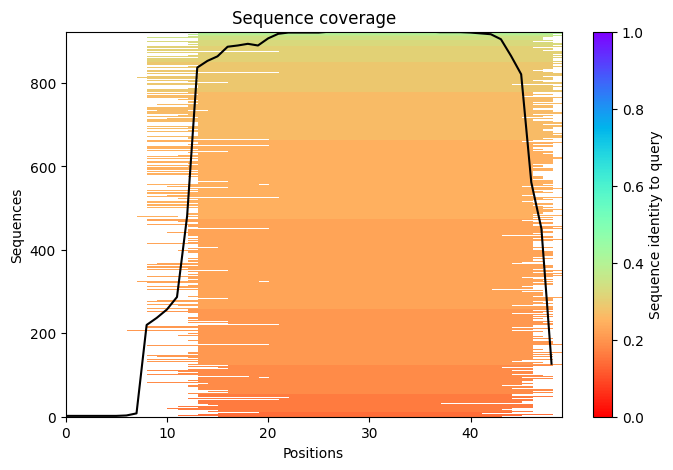

2026-11-03 12:58:06,920 Padding length to 59
2026-11-03 12:58:32,976 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=77.8 pTM=0.434
2026-11-03 12:58:36,704 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=77.1 pTM=0.435 tol=0.93
2026-11-03 12:58:40,493 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=77.9 pTM=0.451 tol=0.833
2026-11-03 12:58:44,808 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=77.8 pTM=0.447 tol=0.586
2026-11-03 12:58:44,809 alphafold2_ptm_model_1_seed_000 took 37.9s (3 recycles)


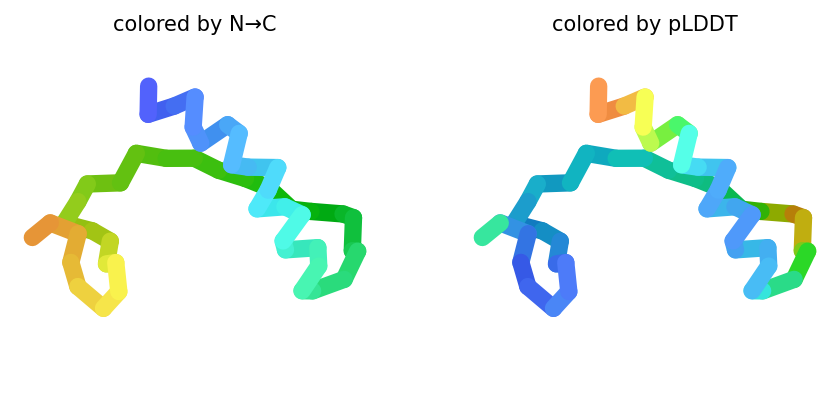

2026-11-03 12:58:48,665 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=72.4 pTM=0.419
2026-11-03 12:58:52,379 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=69.4 pTM=0.417 tol=0.974
2026-11-03 12:58:56,034 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=70.7 pTM=0.426 tol=1.39
2026-11-03 12:58:59,649 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=68.6 pTM=0.415 tol=0.626
2026-11-03 12:58:59,650 alphafold2_ptm_model_2_seed_000 took 14.8s (3 recycles)


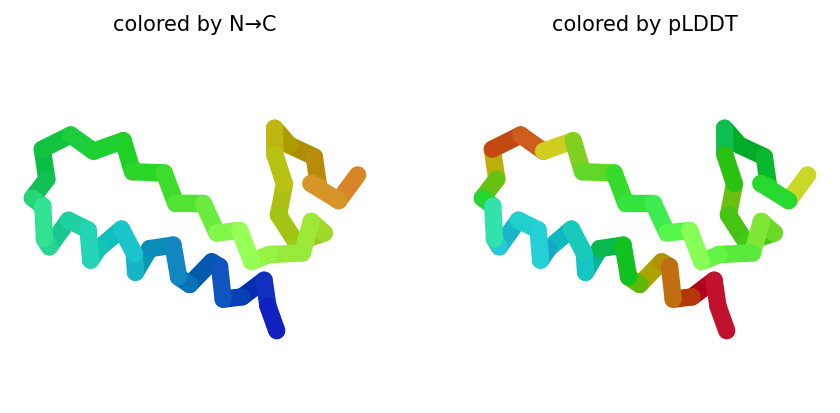

2026-11-03 12:59:03,304 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=84.6 pTM=0.52
2026-11-03 12:59:06,845 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=85.2 pTM=0.529 tol=1.17
2026-11-03 12:59:10,369 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=85.5 pTM=0.524 tol=0.292
2026-11-03 12:59:13,859 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=86 pTM=0.531 tol=0.169
2026-11-03 12:59:13,860 alphafold2_ptm_model_3_seed_000 took 14.1s (3 recycles)


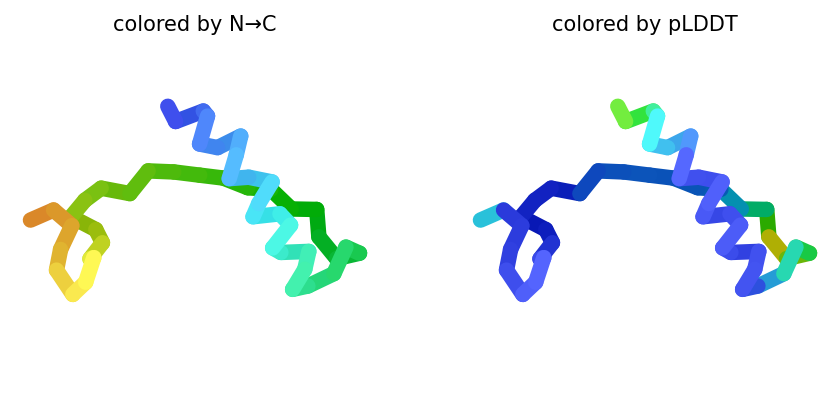

2026-11-03 12:59:17,424 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=82.9 pTM=0.517
2026-11-03 12:59:20,909 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=83.7 pTM=0.524 tol=0.903
2026-11-03 12:59:24,395 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=84.2 pTM=0.531 tol=0.401
2026-11-03 12:59:27,883 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=85.6 pTM=0.546 tol=0.218
2026-11-03 12:59:27,884 alphafold2_ptm_model_4_seed_000 took 14.0s (3 recycles)


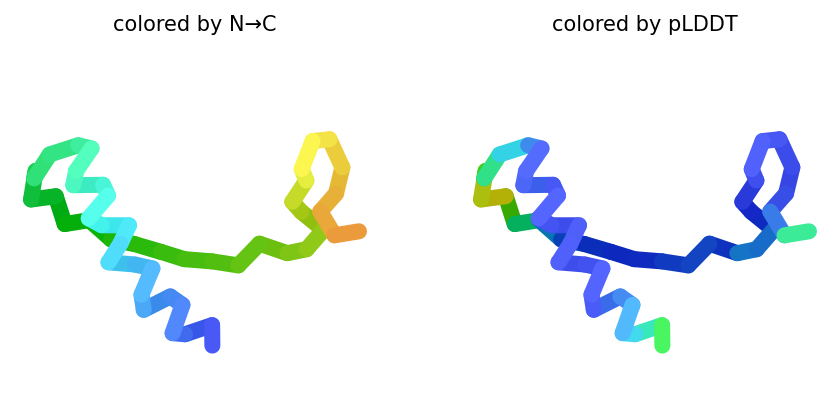

2026-11-03 12:59:31,474 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.507
2026-11-03 12:59:34,986 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=83.1 pTM=0.489 tol=0.583
2026-11-03 12:59:38,499 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=82.3 pTM=0.481 tol=0.321
2026-11-03 12:59:42,025 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=83.4 pTM=0.491 tol=0.229
2026-11-03 12:59:42,026 alphafold2_ptm_model_5_seed_000 took 14.1s (3 recycles)


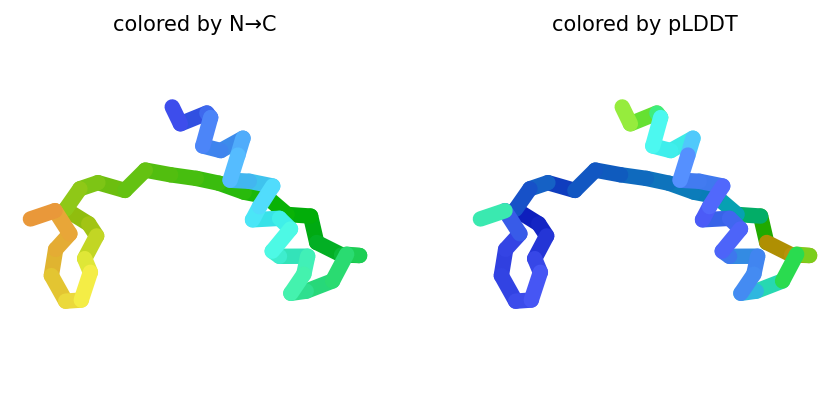

2026-11-03 12:59:42,096 reranking models by 'plddt' metric
2026-11-03 12:59:42,096 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=86 pTM=0.531
2026-11-03 12:59:42,097 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=85.6 pTM=0.546
2026-11-03 12:59:42,097 rank_003_alphafold2_ptm_model_5_seed_000 pLDDT=83.4 pTM=0.491
2026-11-03 12:59:42,097 rank_004_alphafold2_ptm_model_1_seed_000 pLDDT=77.8 pTM=0.447
2026-11-03 12:59:42,098 rank_005_alphafold2_ptm_model_2_seed_000 pLDDT=68.6 pTM=0.415
2026-11-03 12:59:43,427 Query 2/9: proteina_C (length 49)


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:00 remaining: 00:00]


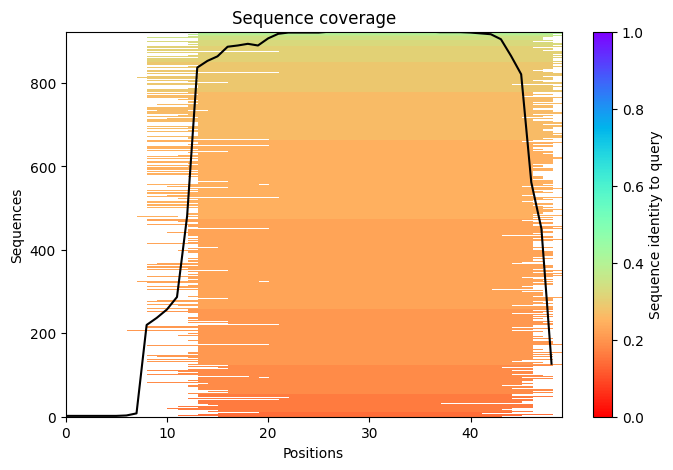

2026-11-03 12:59:45,222 Padding length to 59
2026-11-03 12:59:48,902 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=77.8 pTM=0.434
2026-11-03 12:59:52,482 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=77.1 pTM=0.435 tol=0.93
2026-11-03 12:59:56,087 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=77.9 pTM=0.451 tol=0.833
2026-11-03 12:59:59,704 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=77.8 pTM=0.447 tol=0.586
2026-11-03 12:59:59,705 alphafold2_ptm_model_1_seed_000 took 14.5s (3 recycles)


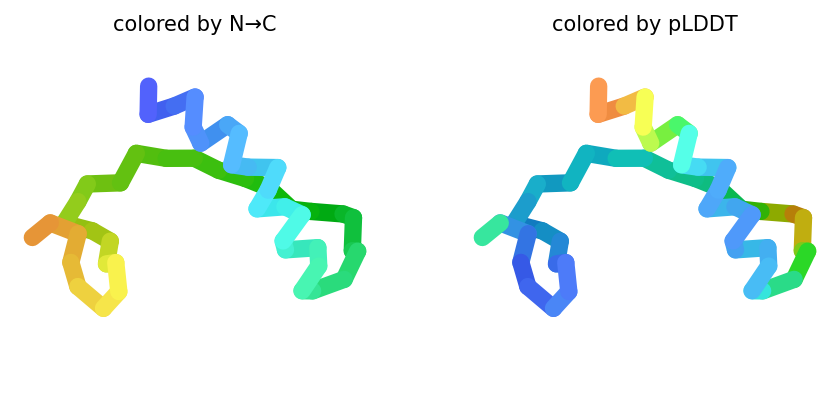

2026-11-03 13:00:03,430 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=72.4 pTM=0.419
2026-11-03 13:00:07,092 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=69.4 pTM=0.417 tol=0.974
2026-11-03 13:00:10,765 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=70.7 pTM=0.426 tol=1.39
2026-11-03 13:00:14,431 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=68.6 pTM=0.415 tol=0.626
2026-11-03 13:00:14,432 alphafold2_ptm_model_2_seed_000 took 14.7s (3 recycles)


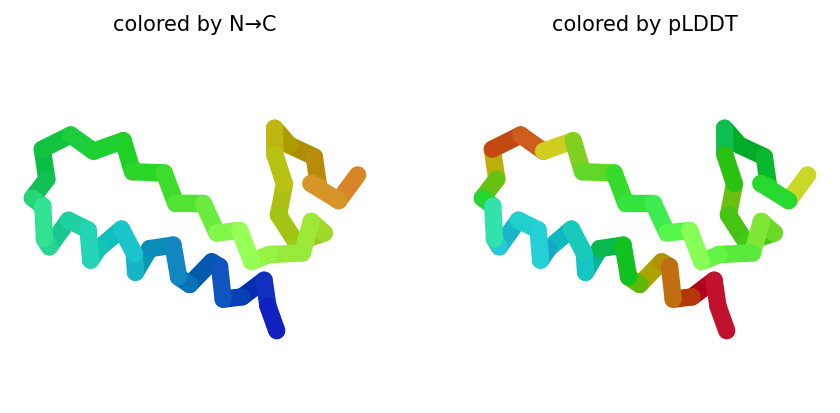

2026-11-03 13:00:18,162 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=84.6 pTM=0.52
2026-11-03 13:00:21,780 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=85.2 pTM=0.529 tol=1.17
2026-11-03 13:00:25,388 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=85.5 pTM=0.524 tol=0.292
2026-11-03 13:00:28,958 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=86 pTM=0.531 tol=0.169
2026-11-03 13:00:28,959 alphafold2_ptm_model_3_seed_000 took 14.4s (3 recycles)


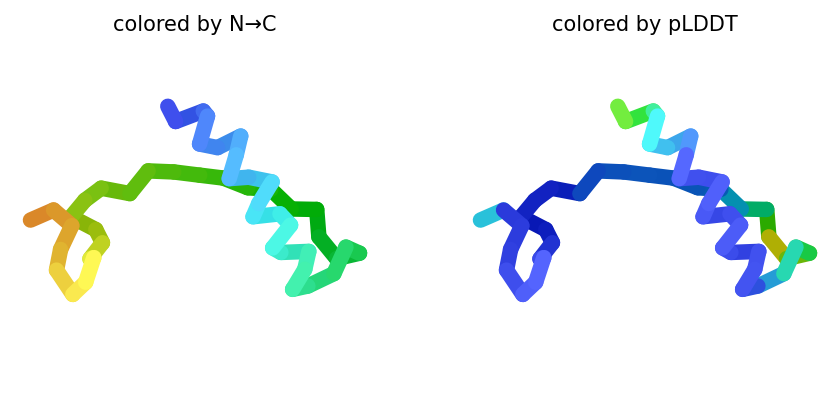

2026-11-03 13:00:32,609 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=82.9 pTM=0.517
2026-11-03 13:00:36,162 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=83.7 pTM=0.524 tol=0.903
2026-11-03 13:00:39,705 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=84.2 pTM=0.531 tol=0.401
2026-11-03 13:00:43,241 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=85.6 pTM=0.546 tol=0.218
2026-11-03 13:00:43,242 alphafold2_ptm_model_4_seed_000 took 14.2s (3 recycles)


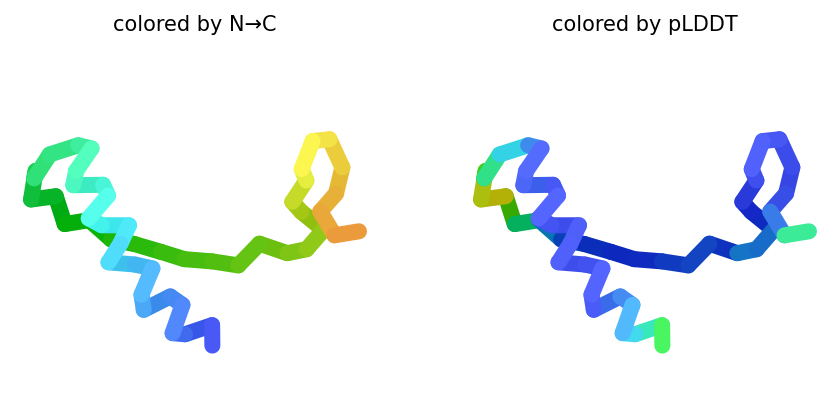

2026-11-03 13:00:46,854 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.507
2026-11-03 13:00:50,388 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=83.1 pTM=0.489 tol=0.583
2026-11-03 13:00:53,920 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=82.3 pTM=0.481 tol=0.321
2026-11-03 13:00:57,442 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=83.4 pTM=0.491 tol=0.229
2026-11-03 13:00:57,443 alphafold2_ptm_model_5_seed_000 took 14.1s (3 recycles)


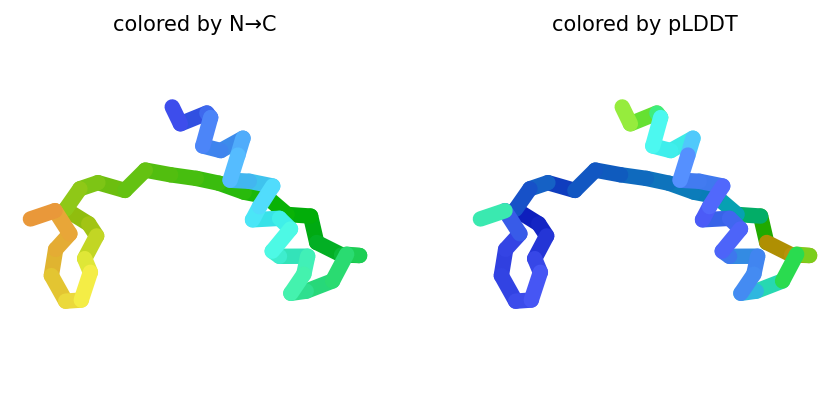

2026-11-03 13:00:57,526 reranking models by 'plddt' metric
2026-11-03 13:00:57,526 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=86 pTM=0.531
2026-11-03 13:00:57,527 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=85.6 pTM=0.546
2026-11-03 13:00:57,527 rank_003_alphafold2_ptm_model_5_seed_000 pLDDT=83.4 pTM=0.491
2026-11-03 13:00:57,527 rank_004_alphafold2_ptm_model_1_seed_000 pLDDT=77.8 pTM=0.447
2026-11-03 13:00:57,527 rank_005_alphafold2_ptm_model_2_seed_000 pLDDT=68.6 pTM=0.415
2026-11-03 13:00:58,578 Query 3/9: proteina_D (length 49)


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:00 remaining: 00:00]


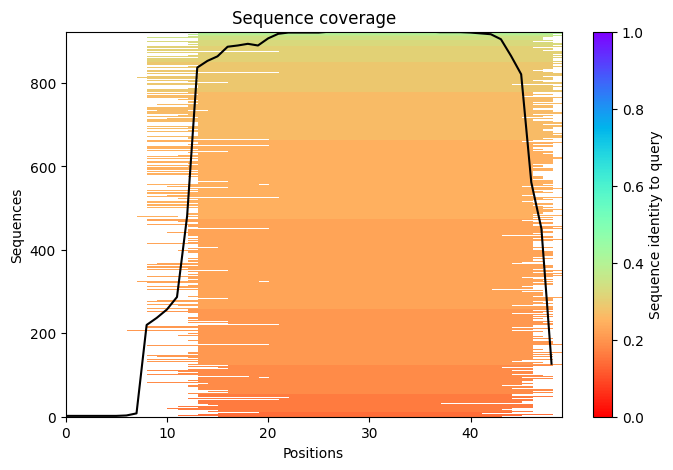

2026-11-03 13:00:59,973 Padding length to 59
2026-11-03 13:01:03,649 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=77.8 pTM=0.434
2026-11-03 13:01:07,176 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=77.1 pTM=0.435 tol=0.93
2026-11-03 13:01:10,720 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=77.9 pTM=0.451 tol=0.833
2026-11-03 13:01:14,278 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=77.8 pTM=0.447 tol=0.586
2026-11-03 13:01:14,279 alphafold2_ptm_model_1_seed_000 took 14.3s (3 recycles)


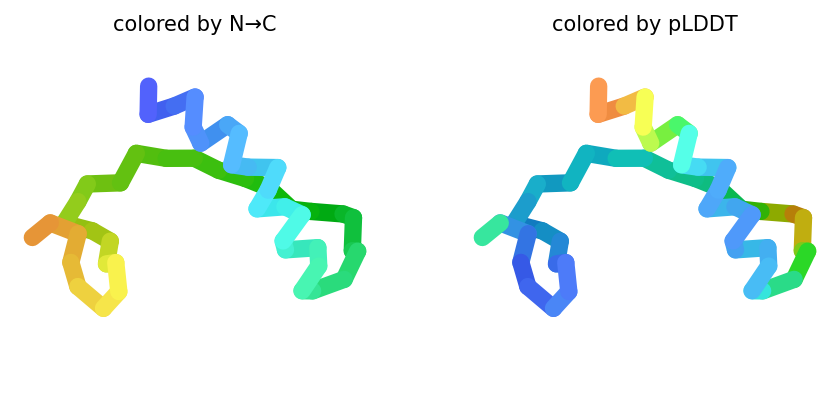

2026-11-03 13:01:18,026 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=72.4 pTM=0.419
2026-11-03 13:01:21,628 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=69.4 pTM=0.417 tol=0.974
2026-11-03 13:01:25,246 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=70.7 pTM=0.426 tol=1.39
2026-11-03 13:01:28,849 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=68.6 pTM=0.415 tol=0.626
2026-11-03 13:01:28,851 alphafold2_ptm_model_2_seed_000 took 14.4s (3 recycles)


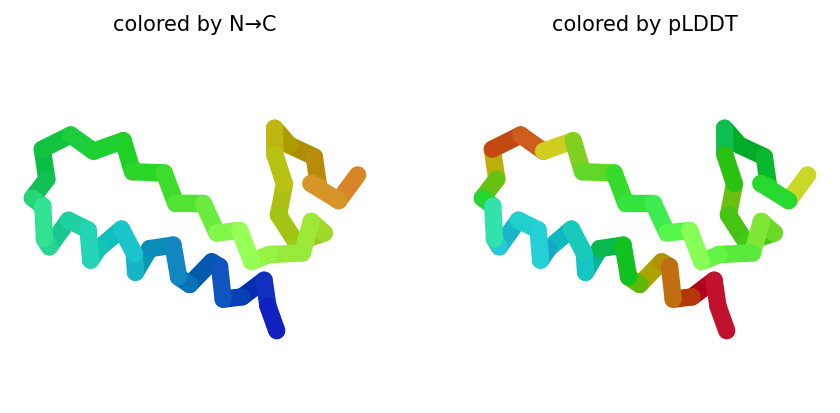

2026-11-03 13:01:32,974 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=84.6 pTM=0.52
2026-11-03 13:01:36,583 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=85.2 pTM=0.529 tol=1.17
2026-11-03 13:01:40,193 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=85.5 pTM=0.524 tol=0.292
2026-11-03 13:01:43,801 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=86 pTM=0.531 tol=0.169
2026-11-03 13:01:43,803 alphafold2_ptm_model_3_seed_000 took 14.5s (3 recycles)


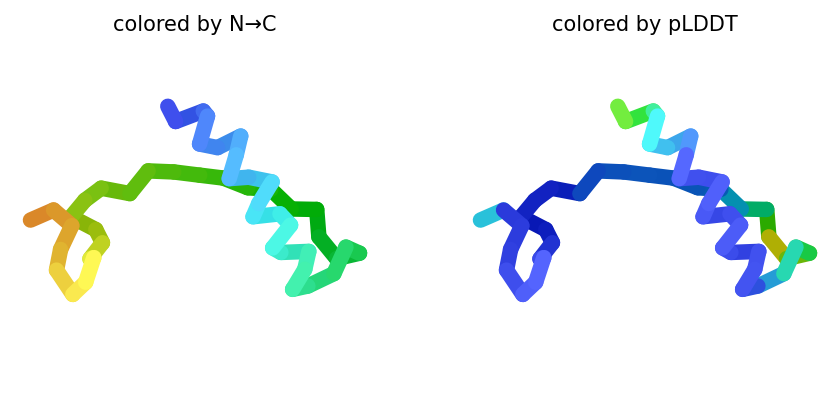

2026-11-03 13:01:47,487 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=82.9 pTM=0.517
2026-11-03 13:01:51,071 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=83.7 pTM=0.524 tol=0.903
2026-11-03 13:01:54,653 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=84.2 pTM=0.531 tol=0.401
2026-11-03 13:01:58,226 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=85.6 pTM=0.546 tol=0.218
2026-11-03 13:01:58,227 alphafold2_ptm_model_4_seed_000 took 14.4s (3 recycles)


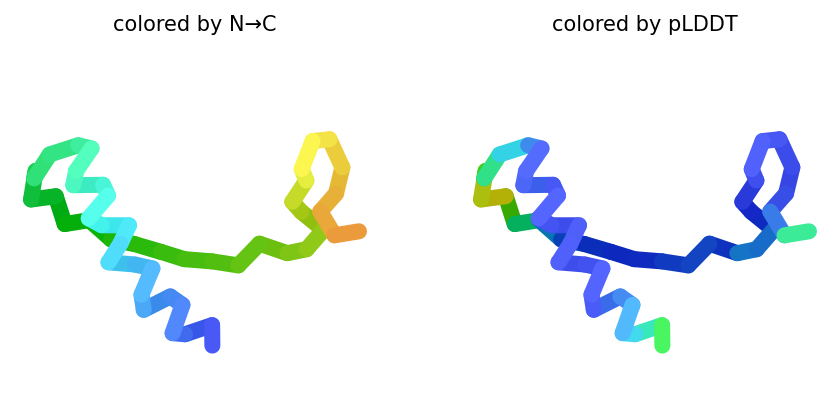

2026-11-03 13:02:01,889 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.507
2026-11-03 13:02:05,455 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=83.1 pTM=0.489 tol=0.583
2026-11-03 13:02:09,039 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=82.3 pTM=0.481 tol=0.321
2026-11-03 13:02:12,589 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=83.4 pTM=0.491 tol=0.229
2026-11-03 13:02:12,590 alphafold2_ptm_model_5_seed_000 took 14.3s (3 recycles)


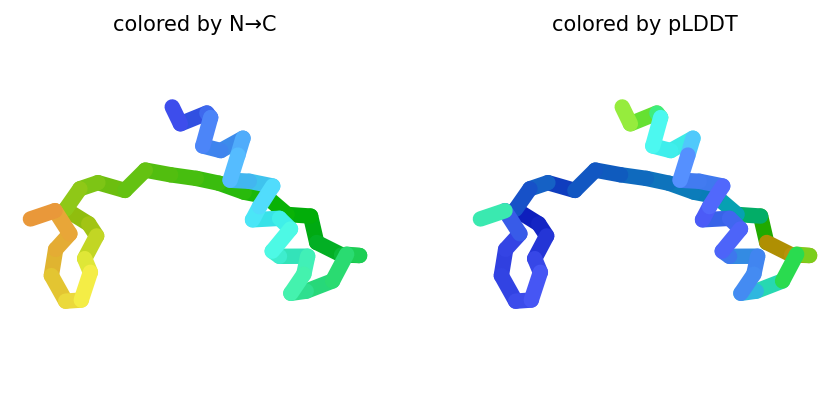

2026-11-03 13:02:12,664 reranking models by 'plddt' metric
2026-11-03 13:02:12,665 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=86 pTM=0.531
2026-11-03 13:02:12,665 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=85.6 pTM=0.546
2026-11-03 13:02:12,665 rank_003_alphafold2_ptm_model_5_seed_000 pLDDT=83.4 pTM=0.491
2026-11-03 13:02:12,666 rank_004_alphafold2_ptm_model_1_seed_000 pLDDT=77.8 pTM=0.447
2026-11-03 13:02:12,666 rank_005_alphafold2_ptm_model_2_seed_000 pLDDT=68.6 pTM=0.415
2026-11-03 13:02:13,731 Query 4/9: proteina_E (length 49)


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:00 remaining: 00:00]


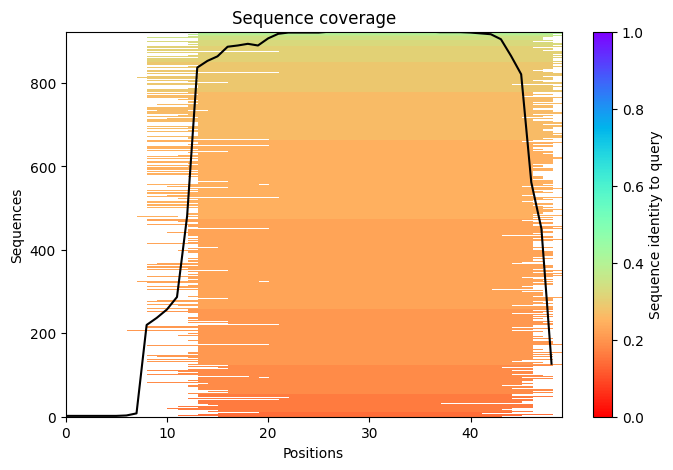

2026-11-03 13:02:15,081 Padding length to 59
2026-11-03 13:02:18,762 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=77.8 pTM=0.434
2026-11-03 13:02:22,294 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=77.1 pTM=0.435 tol=0.93
2026-11-03 13:02:25,849 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=77.9 pTM=0.451 tol=0.833
2026-11-03 13:02:29,410 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=77.8 pTM=0.447 tol=0.586
2026-11-03 13:02:29,411 alphafold2_ptm_model_1_seed_000 took 14.3s (3 recycles)


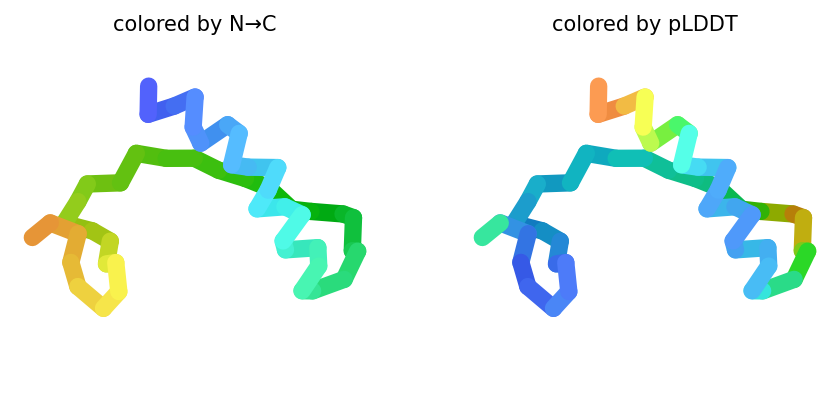

2026-11-03 13:02:33,088 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=72.4 pTM=0.419
2026-11-03 13:02:36,668 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=69.4 pTM=0.417 tol=0.974
2026-11-03 13:02:40,258 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=70.7 pTM=0.426 tol=1.39
2026-11-03 13:02:43,854 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=68.6 pTM=0.415 tol=0.626
2026-11-03 13:02:43,856 alphafold2_ptm_model_2_seed_000 took 14.4s (3 recycles)


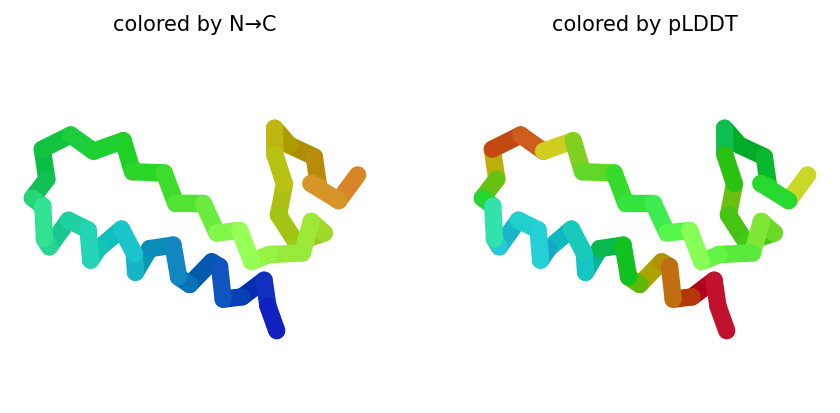

2026-11-03 13:02:47,527 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=84.6 pTM=0.52
2026-11-03 13:02:51,119 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=85.2 pTM=0.529 tol=1.17
2026-11-03 13:02:54,707 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=85.5 pTM=0.524 tol=0.292
2026-11-03 13:02:58,299 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=86 pTM=0.531 tol=0.169
2026-11-03 13:02:58,300 alphafold2_ptm_model_3_seed_000 took 14.4s (3 recycles)


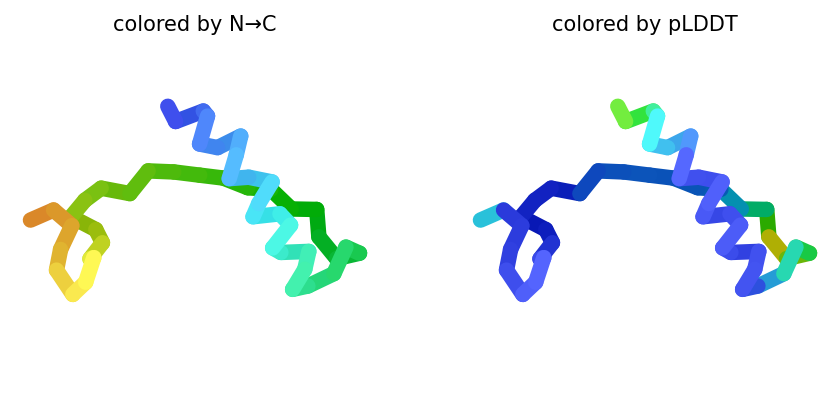

2026-11-03 13:03:02,031 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=82.9 pTM=0.517
2026-11-03 13:03:05,623 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=83.7 pTM=0.524 tol=0.903
2026-11-03 13:03:09,198 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=84.2 pTM=0.531 tol=0.401
2026-11-03 13:03:12,776 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=85.6 pTM=0.546 tol=0.218
2026-11-03 13:03:12,777 alphafold2_ptm_model_4_seed_000 took 14.4s (3 recycles)


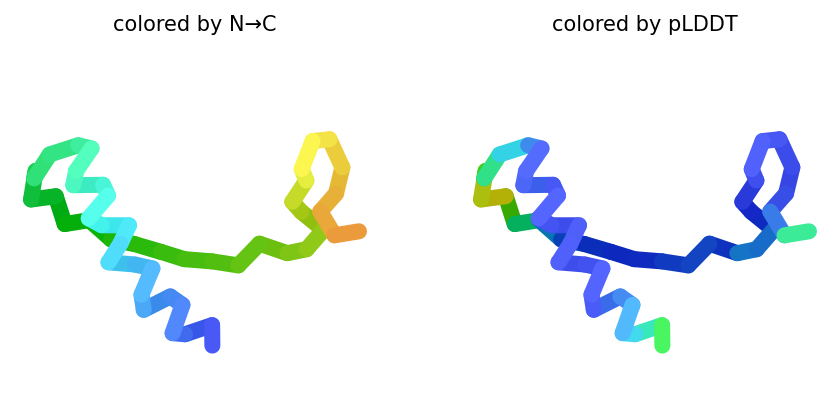

2026-11-03 13:03:16,431 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.507
2026-11-03 13:03:19,995 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=83.1 pTM=0.489 tol=0.583
2026-11-03 13:03:23,561 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=82.3 pTM=0.481 tol=0.321
2026-11-03 13:03:27,131 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=83.4 pTM=0.491 tol=0.229
2026-11-03 13:03:27,132 alphafold2_ptm_model_5_seed_000 took 14.3s (3 recycles)


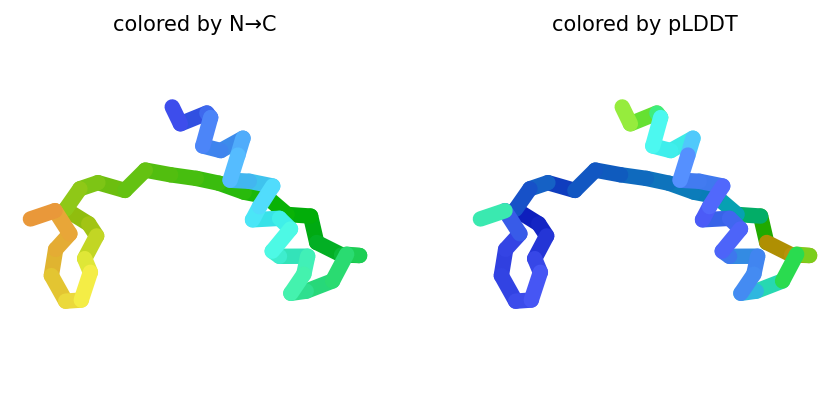

2026-11-03 13:03:27,207 reranking models by 'plddt' metric
2026-11-03 13:03:27,208 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=86 pTM=0.531
2026-11-03 13:03:27,208 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=85.6 pTM=0.546
2026-11-03 13:03:27,209 rank_003_alphafold2_ptm_model_5_seed_000 pLDDT=83.4 pTM=0.491
2026-11-03 13:03:27,209 rank_004_alphafold2_ptm_model_1_seed_000 pLDDT=77.8 pTM=0.447
2026-11-03 13:03:27,209 rank_005_alphafold2_ptm_model_2_seed_000 pLDDT=68.6 pTM=0.415
2026-11-03 13:03:28,259 Query 5/9: proteina_F (length 49)


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:00 remaining: 00:00]


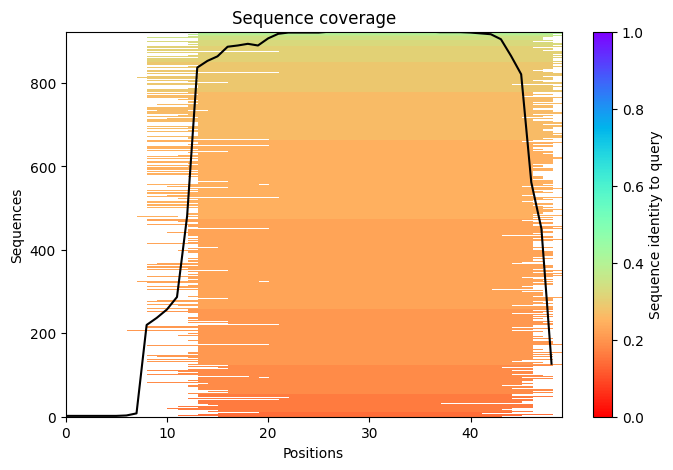

2026-11-03 13:03:29,496 Padding length to 59
2026-11-03 13:03:33,181 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=77.8 pTM=0.434
2026-11-03 13:03:36,731 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=77.1 pTM=0.435 tol=0.93
2026-11-03 13:03:40,290 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=77.9 pTM=0.451 tol=0.833
2026-11-03 13:03:43,843 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=77.8 pTM=0.447 tol=0.586
2026-11-03 13:03:43,844 alphafold2_ptm_model_1_seed_000 took 14.3s (3 recycles)


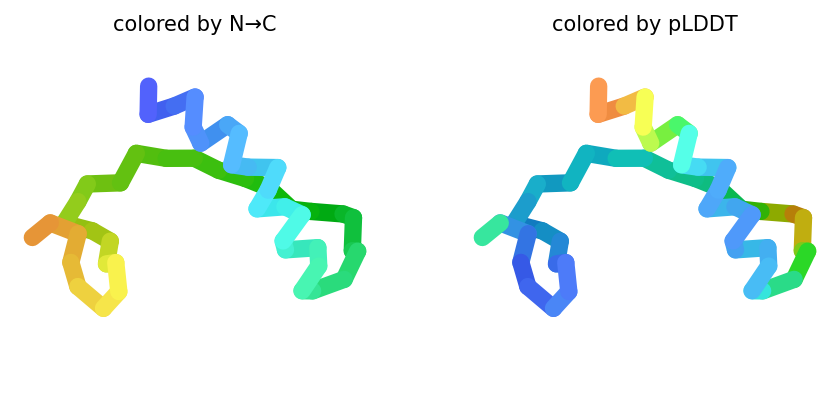

2026-11-03 13:03:47,490 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=72.4 pTM=0.419
2026-11-03 13:03:51,062 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=69.4 pTM=0.417 tol=0.974
2026-11-03 13:03:54,641 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=70.7 pTM=0.426 tol=1.39
2026-11-03 13:03:58,222 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=68.6 pTM=0.415 tol=0.626
2026-11-03 13:03:58,223 alphafold2_ptm_model_2_seed_000 took 14.3s (3 recycles)


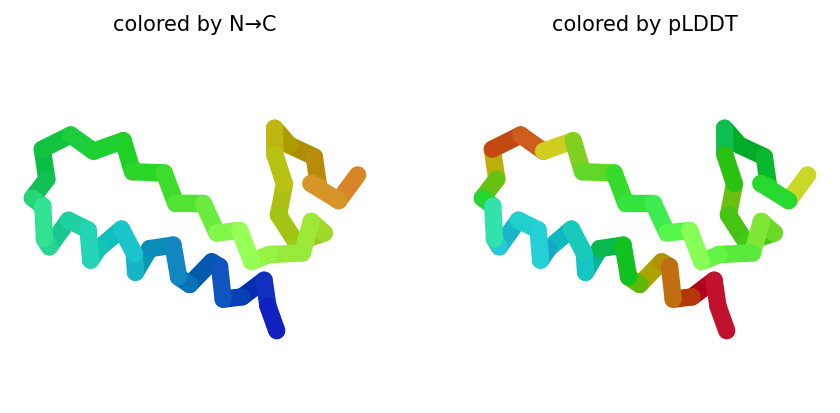

2026-11-03 13:04:01,903 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=84.6 pTM=0.52
2026-11-03 13:04:05,492 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=85.2 pTM=0.529 tol=1.17
2026-11-03 13:04:09,066 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=85.5 pTM=0.524 tol=0.292
2026-11-03 13:04:12,650 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=86 pTM=0.531 tol=0.169
2026-11-03 13:04:12,651 alphafold2_ptm_model_3_seed_000 took 14.4s (3 recycles)


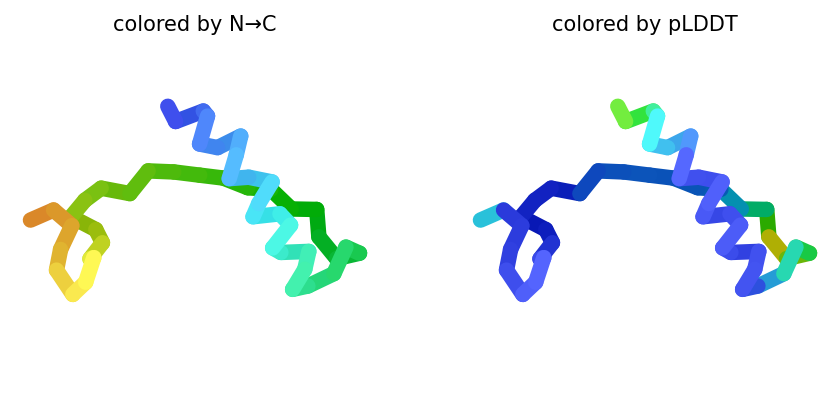

2026-11-03 13:04:16,319 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=82.9 pTM=0.517
2026-11-03 13:04:19,906 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=83.7 pTM=0.524 tol=0.903
2026-11-03 13:04:23,480 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=84.2 pTM=0.531 tol=0.401
2026-11-03 13:04:27,065 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=85.6 pTM=0.546 tol=0.218
2026-11-03 13:04:27,066 alphafold2_ptm_model_4_seed_000 took 14.3s (3 recycles)


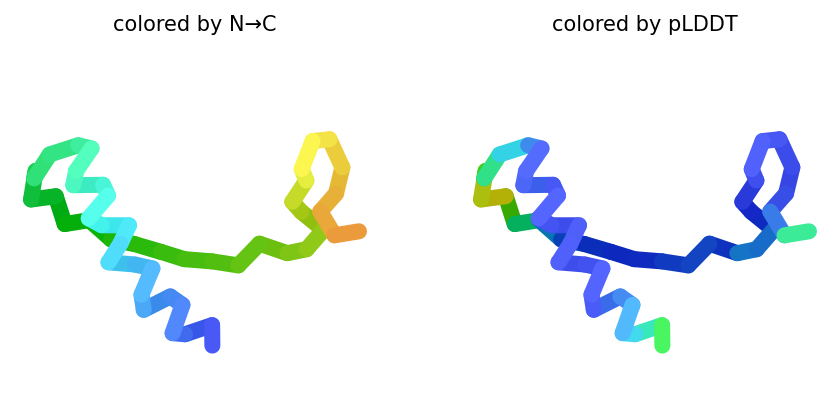

2026-11-03 13:04:30,728 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.507
2026-11-03 13:04:34,296 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=83.1 pTM=0.489 tol=0.583
2026-11-03 13:04:37,864 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=82.3 pTM=0.481 tol=0.321
2026-11-03 13:04:41,430 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=83.4 pTM=0.491 tol=0.229
2026-11-03 13:04:41,432 alphafold2_ptm_model_5_seed_000 took 14.3s (3 recycles)


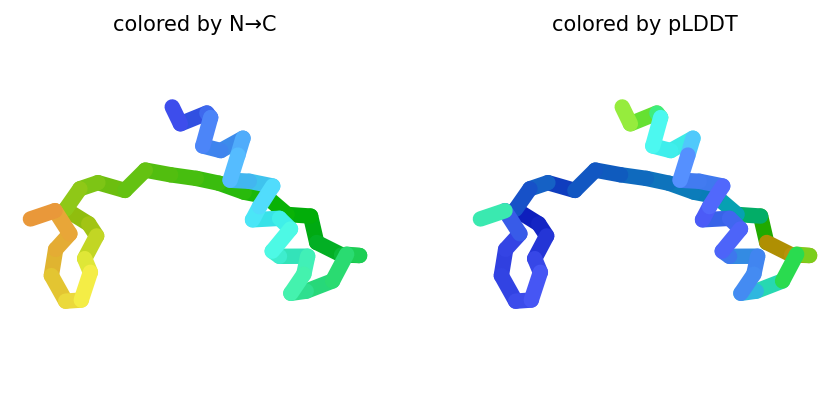

2026-11-03 13:04:41,544 reranking models by 'plddt' metric
2026-11-03 13:04:41,544 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=86 pTM=0.531
2026-11-03 13:04:41,544 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=85.6 pTM=0.546
2026-11-03 13:04:41,545 rank_003_alphafold2_ptm_model_5_seed_000 pLDDT=83.4 pTM=0.491
2026-11-03 13:04:41,545 rank_004_alphafold2_ptm_model_1_seed_000 pLDDT=77.8 pTM=0.447
2026-11-03 13:04:41,545 rank_005_alphafold2_ptm_model_2_seed_000 pLDDT=68.6 pTM=0.415
2026-11-03 13:04:43,093 Query 6/9: proteina_G (length 49)


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:00 remaining: 00:00]


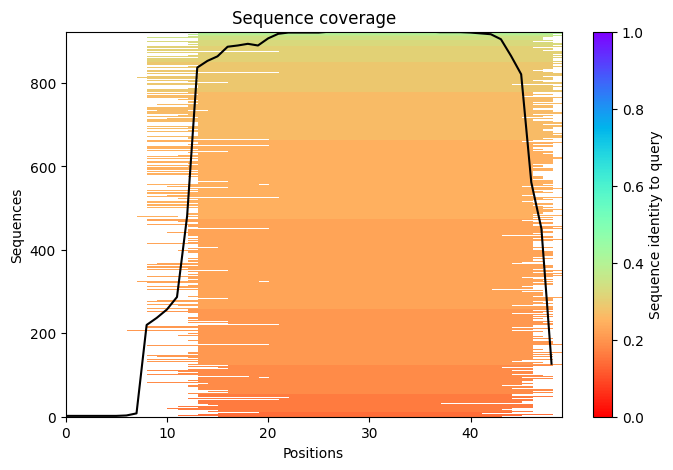

2026-11-03 13:04:44,451 Padding length to 59
2026-11-03 13:04:48,146 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=77.8 pTM=0.434
2026-11-03 13:04:51,699 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=77.1 pTM=0.435 tol=0.93
2026-11-03 13:04:55,258 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=77.9 pTM=0.451 tol=0.833
2026-11-03 13:04:58,831 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=77.8 pTM=0.447 tol=0.586
2026-11-03 13:04:58,832 alphafold2_ptm_model_1_seed_000 took 14.4s (3 recycles)


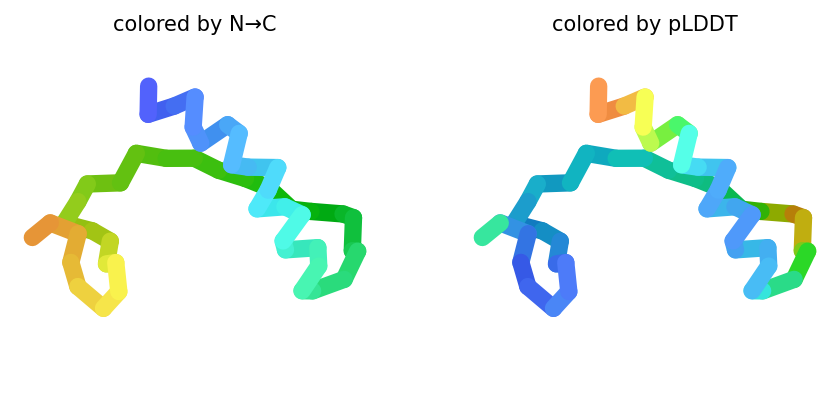

2026-11-03 13:05:02,497 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=72.4 pTM=0.419
2026-11-03 13:05:06,101 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=69.4 pTM=0.417 tol=0.974
2026-11-03 13:05:09,720 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=70.7 pTM=0.426 tol=1.39
2026-11-03 13:05:13,331 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=68.6 pTM=0.415 tol=0.626
2026-11-03 13:05:13,332 alphafold2_ptm_model_2_seed_000 took 14.4s (3 recycles)


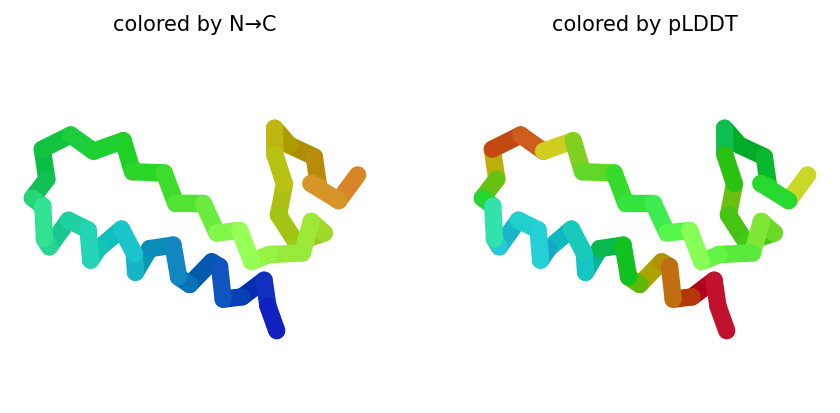

2026-11-03 13:05:17,037 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=84.6 pTM=0.52
2026-11-03 13:05:20,619 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=85.2 pTM=0.529 tol=1.17
2026-11-03 13:05:24,208 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=85.5 pTM=0.524 tol=0.292
2026-11-03 13:05:27,788 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=86 pTM=0.531 tol=0.169
2026-11-03 13:05:27,789 alphafold2_ptm_model_3_seed_000 took 14.4s (3 recycles)


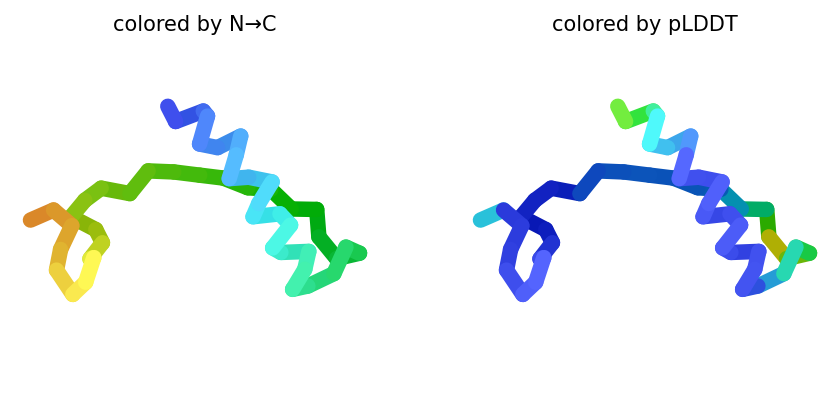

2026-11-03 13:05:31,471 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=82.9 pTM=0.517
2026-11-03 13:05:35,039 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=83.7 pTM=0.524 tol=0.903
2026-11-03 13:05:38,619 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=84.2 pTM=0.531 tol=0.401
2026-11-03 13:05:42,185 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=85.6 pTM=0.546 tol=0.218
2026-11-03 13:05:42,186 alphafold2_ptm_model_4_seed_000 took 14.3s (3 recycles)


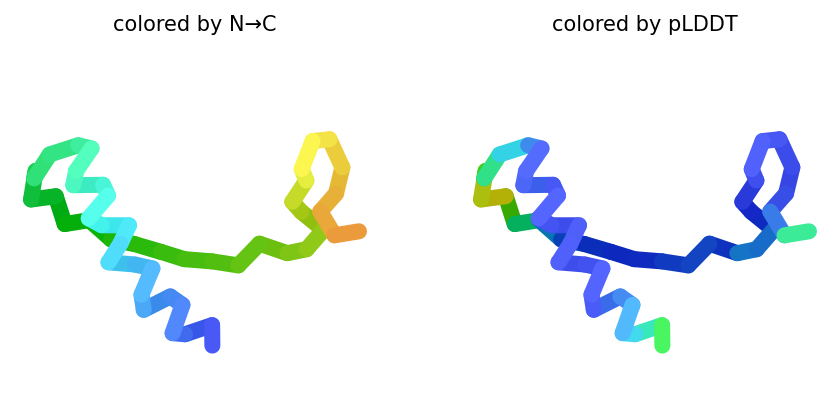

2026-11-03 13:05:45,836 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.507
2026-11-03 13:05:49,402 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=83.1 pTM=0.489 tol=0.583
2026-11-03 13:05:52,956 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=82.3 pTM=0.481 tol=0.321
2026-11-03 13:05:56,523 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=83.4 pTM=0.491 tol=0.229
2026-11-03 13:05:56,524 alphafold2_ptm_model_5_seed_000 took 14.3s (3 recycles)


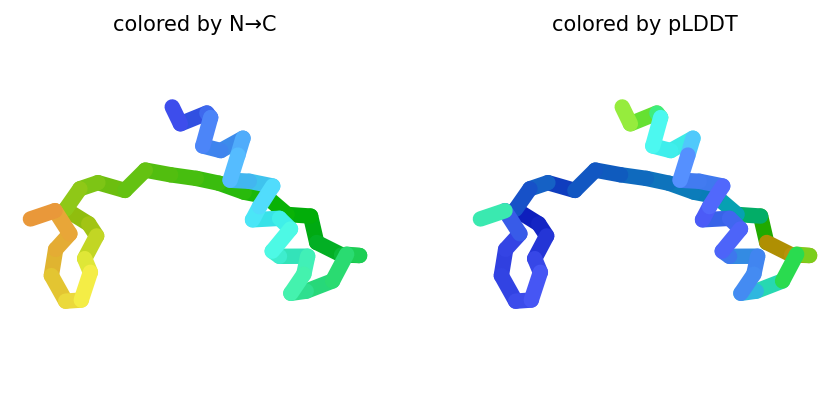

2026-11-03 13:05:56,596 reranking models by 'plddt' metric
2026-11-03 13:05:56,596 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=86 pTM=0.531
2026-11-03 13:05:56,598 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=85.6 pTM=0.546
2026-11-03 13:05:56,598 rank_003_alphafold2_ptm_model_5_seed_000 pLDDT=83.4 pTM=0.491
2026-11-03 13:05:56,598 rank_004_alphafold2_ptm_model_1_seed_000 pLDDT=77.8 pTM=0.447
2026-11-03 13:05:56,598 rank_005_alphafold2_ptm_model_2_seed_000 pLDDT=68.6 pTM=0.415
2026-11-03 13:05:57,656 Query 7/9: proteina_H (length 49)


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:00 remaining: 00:00]


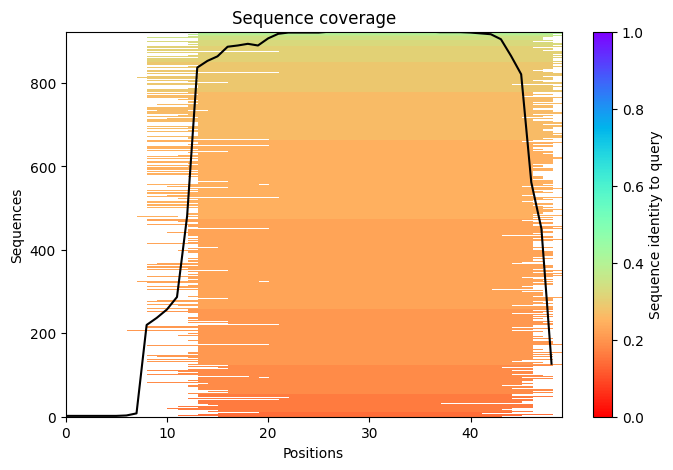

2026-11-03 13:05:59,190 Padding length to 59
2026-11-03 13:06:02,895 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=77.8 pTM=0.434
2026-11-03 13:06:06,444 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=77.1 pTM=0.435 tol=0.93
2026-11-03 13:06:09,999 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=77.9 pTM=0.451 tol=0.833
2026-11-03 13:06:13,580 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=77.8 pTM=0.447 tol=0.586
2026-11-03 13:06:13,581 alphafold2_ptm_model_1_seed_000 took 14.4s (3 recycles)


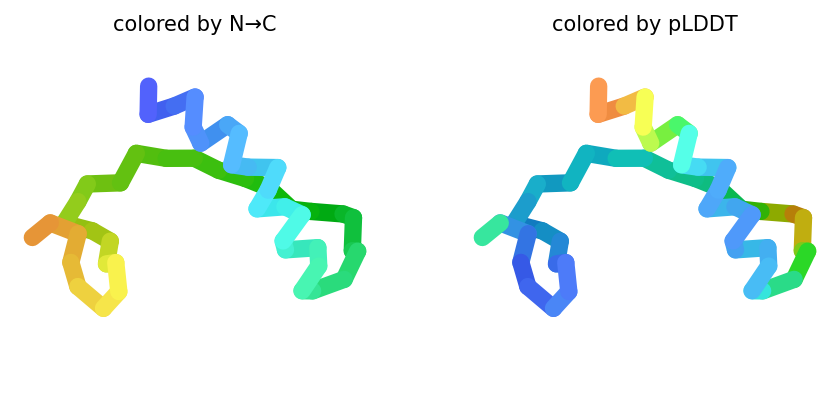

2026-11-03 13:06:17,317 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=72.4 pTM=0.419
2026-11-03 13:06:20,924 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=69.4 pTM=0.417 tol=0.974
2026-11-03 13:06:24,522 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=70.7 pTM=0.426 tol=1.39
2026-11-03 13:06:28,140 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=68.6 pTM=0.415 tol=0.626
2026-11-03 13:06:28,141 alphafold2_ptm_model_2_seed_000 took 14.5s (3 recycles)


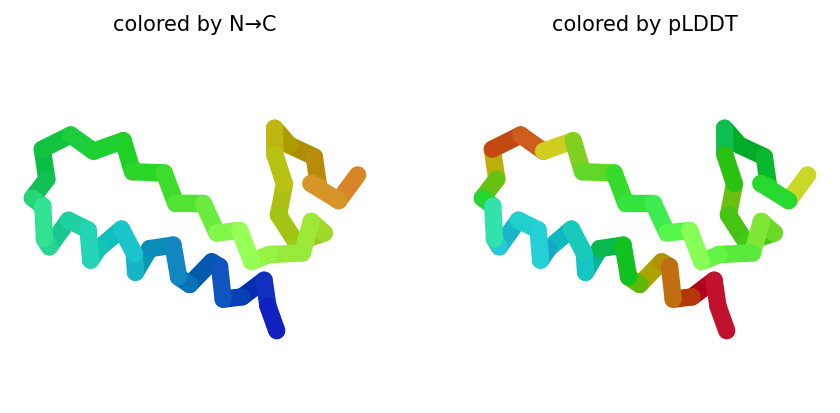

2026-11-03 13:06:31,827 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=84.6 pTM=0.52
2026-11-03 13:06:35,439 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=85.2 pTM=0.529 tol=1.17
2026-11-03 13:06:39,039 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=85.5 pTM=0.524 tol=0.292
2026-11-03 13:06:42,637 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=86 pTM=0.531 tol=0.169
2026-11-03 13:06:42,638 alphafold2_ptm_model_3_seed_000 took 14.4s (3 recycles)


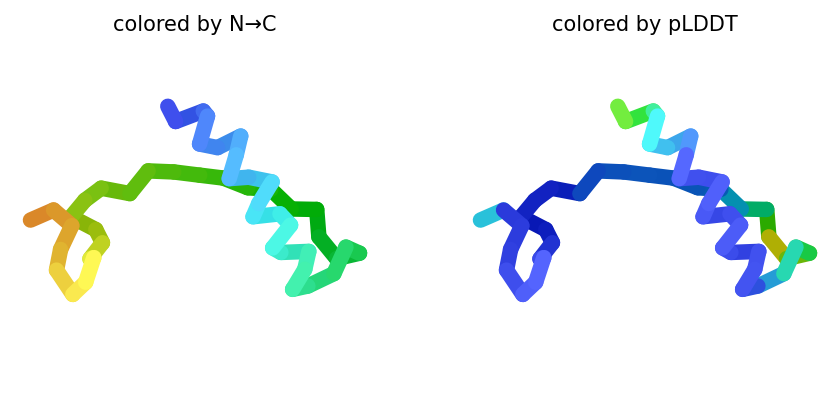

2026-11-03 13:06:46,317 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=82.9 pTM=0.517
2026-11-03 13:06:49,904 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=83.7 pTM=0.524 tol=0.903
2026-11-03 13:06:53,482 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=84.2 pTM=0.531 tol=0.401
2026-11-03 13:06:57,066 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=85.6 pTM=0.546 tol=0.218
2026-11-03 13:06:57,067 alphafold2_ptm_model_4_seed_000 took 14.4s (3 recycles)


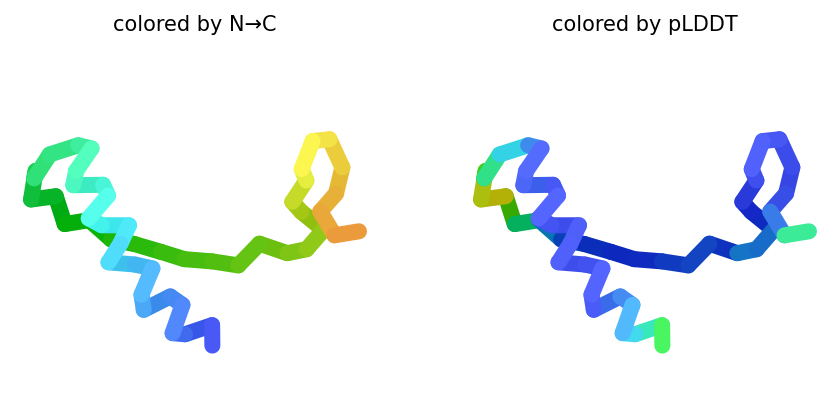

2026-11-03 13:07:00,719 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.507
2026-11-03 13:07:04,281 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=83.1 pTM=0.489 tol=0.583
2026-11-03 13:07:07,834 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=82.3 pTM=0.481 tol=0.321
2026-11-03 13:07:11,382 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=83.4 pTM=0.491 tol=0.229
2026-11-03 13:07:11,383 alphafold2_ptm_model_5_seed_000 took 14.2s (3 recycles)


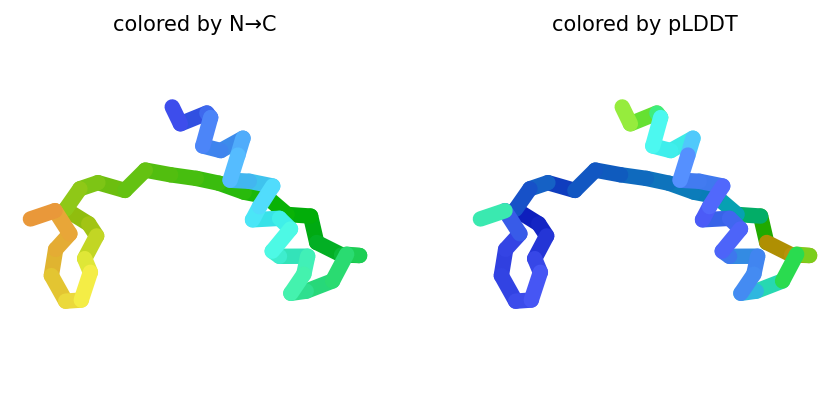

2026-11-03 13:07:11,457 reranking models by 'plddt' metric
2026-11-03 13:07:11,458 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=86 pTM=0.531
2026-11-03 13:07:11,459 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=85.6 pTM=0.546
2026-11-03 13:07:11,459 rank_003_alphafold2_ptm_model_5_seed_000 pLDDT=83.4 pTM=0.491
2026-11-03 13:07:11,459 rank_004_alphafold2_ptm_model_1_seed_000 pLDDT=77.8 pTM=0.447
2026-11-03 13:07:11,460 rank_005_alphafold2_ptm_model_2_seed_000 pLDDT=68.6 pTM=0.415
2026-11-03 13:07:12,831 Query 8/9: proteina_I (length 49)


COMPLETE: 100%|██████████| 150/150 [elapsed: 00:00 remaining: 00:00]


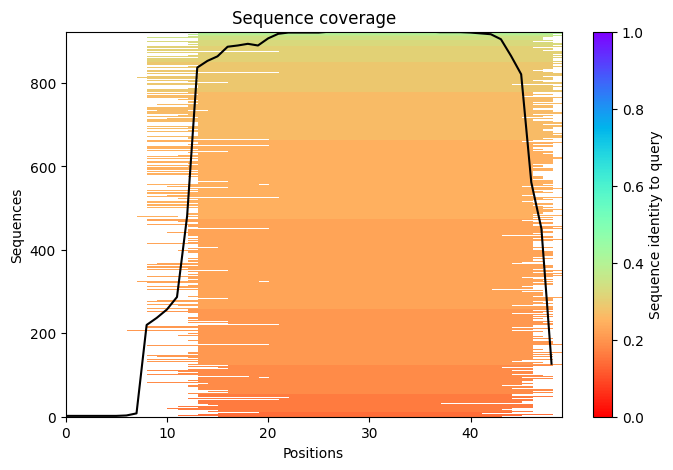

2026-11-03 13:07:14,056 Padding length to 59
2026-11-03 13:07:17,715 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=77.8 pTM=0.434
2026-11-03 13:07:21,249 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=77.1 pTM=0.435 tol=0.93
2026-11-03 13:07:24,801 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=77.9 pTM=0.451 tol=0.833
2026-11-03 13:07:28,365 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=77.8 pTM=0.447 tol=0.586
2026-11-03 13:07:28,366 alphafold2_ptm_model_1_seed_000 took 14.3s (3 recycles)


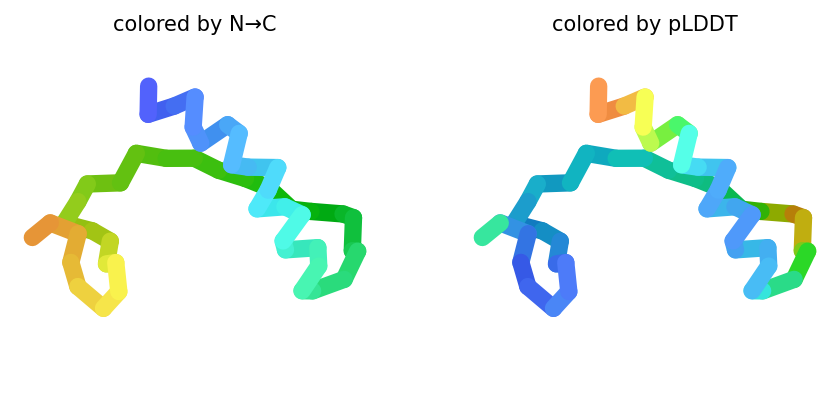

2026-11-03 13:07:32,028 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=72.4 pTM=0.419
2026-11-03 13:07:35,620 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=69.4 pTM=0.417 tol=0.974
2026-11-03 13:07:39,223 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=70.7 pTM=0.426 tol=1.39
2026-11-03 13:07:42,821 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=68.6 pTM=0.415 tol=0.626
2026-11-03 13:07:42,823 alphafold2_ptm_model_2_seed_000 took 14.4s (3 recycles)


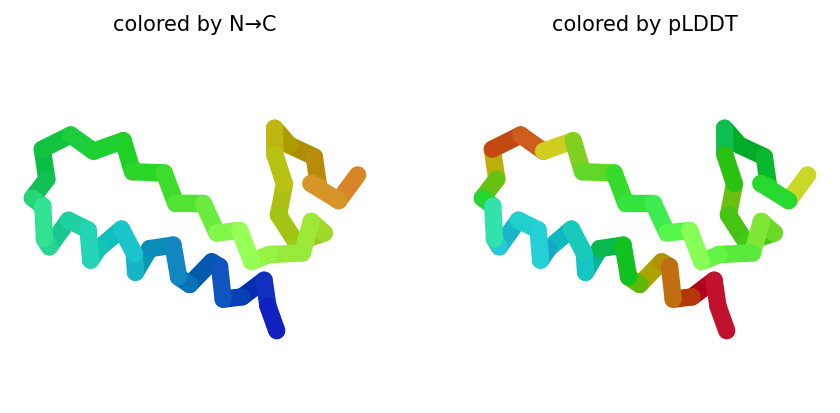

2026-11-03 13:07:46,567 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=84.6 pTM=0.52
2026-11-03 13:07:50,153 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=85.2 pTM=0.529 tol=1.17
2026-11-03 13:07:53,731 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=85.5 pTM=0.524 tol=0.292
2026-11-03 13:07:57,310 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=86 pTM=0.531 tol=0.169
2026-11-03 13:07:57,311 alphafold2_ptm_model_3_seed_000 took 14.4s (3 recycles)


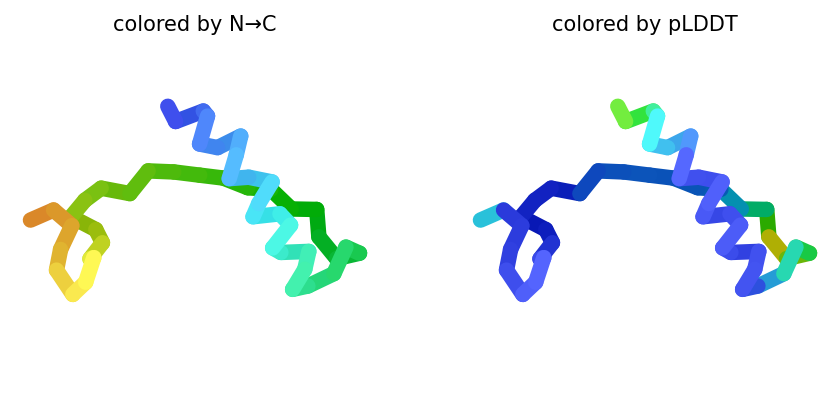

2026-11-03 13:08:01,036 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=82.9 pTM=0.517
2026-11-03 13:08:04,601 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=83.7 pTM=0.524 tol=0.903
2026-11-03 13:08:08,162 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=84.2 pTM=0.531 tol=0.401
2026-11-03 13:08:11,724 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=85.6 pTM=0.546 tol=0.218
2026-11-03 13:08:11,725 alphafold2_ptm_model_4_seed_000 took 14.3s (3 recycles)


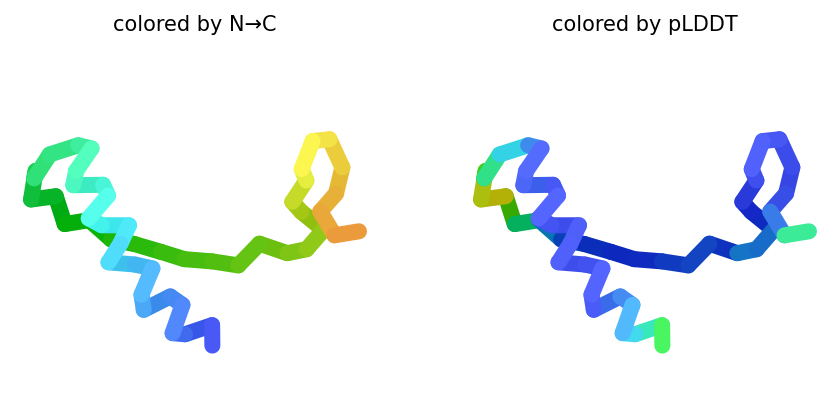

2026-11-03 13:08:15,375 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=85.1 pTM=0.507
2026-11-03 13:08:18,944 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=83.1 pTM=0.489 tol=0.583
2026-11-03 13:08:22,517 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=82.3 pTM=0.481 tol=0.321
2026-11-03 13:08:26,095 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=83.4 pTM=0.491 tol=0.229
2026-11-03 13:08:26,096 alphafold2_ptm_model_5_seed_000 took 14.3s (3 recycles)


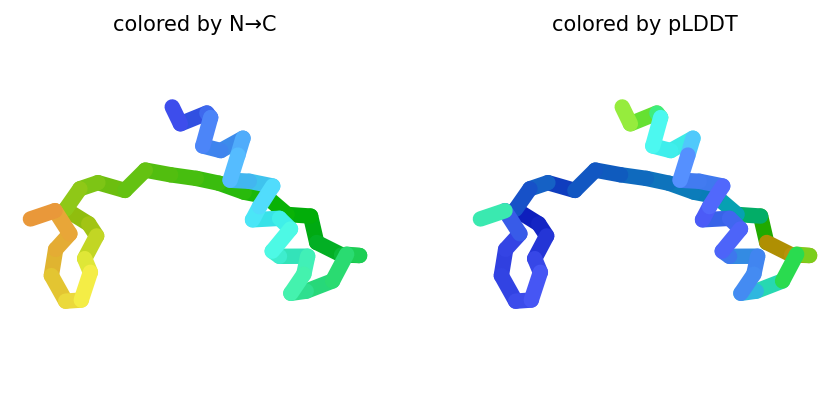

2026-11-03 13:08:26,170 reranking models by 'plddt' metric
2026-11-03 13:08:26,171 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=86 pTM=0.531
2026-11-03 13:08:26,172 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=85.6 pTM=0.546
2026-11-03 13:08:26,172 rank_003_alphafold2_ptm_model_5_seed_000 pLDDT=83.4 pTM=0.491
2026-11-03 13:08:26,172 rank_004_alphafold2_ptm_model_1_seed_000 pLDDT=77.8 pTM=0.447
2026-11-03 13:08:26,173 rank_005_alphafold2_ptm_model_2_seed_000 pLDDT=68.6 pTM=0.415
2026-11-03 13:08:27,268 Query 9/9: proteina_A (length 59)


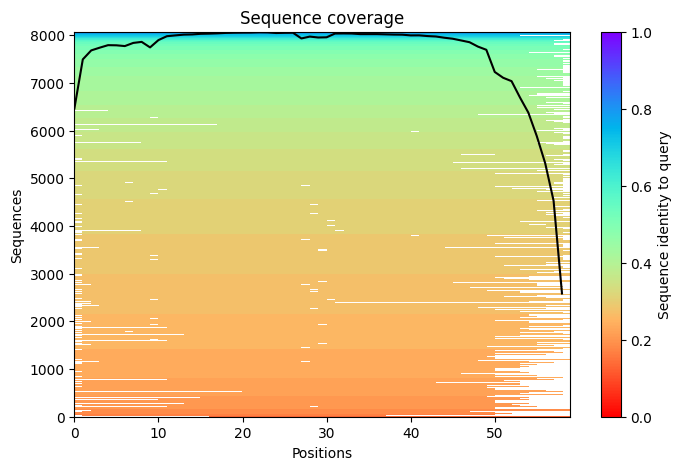

2026-11-03 13:08:32,882 alphafold2_ptm_model_1_seed_000 recycle=0 pLDDT=96.6 pTM=0.753
2026-11-03 13:08:36,473 alphafold2_ptm_model_1_seed_000 recycle=1 pLDDT=96.4 pTM=0.757 tol=0.229
2026-11-03 13:08:40,078 alphafold2_ptm_model_1_seed_000 recycle=2 pLDDT=96.1 pTM=0.753 tol=0.0884
2026-11-03 13:08:43,684 alphafold2_ptm_model_1_seed_000 recycle=3 pLDDT=95.5 pTM=0.75 tol=0.0723
2026-11-03 13:08:43,685 alphafold2_ptm_model_1_seed_000 took 14.5s (3 recycles)


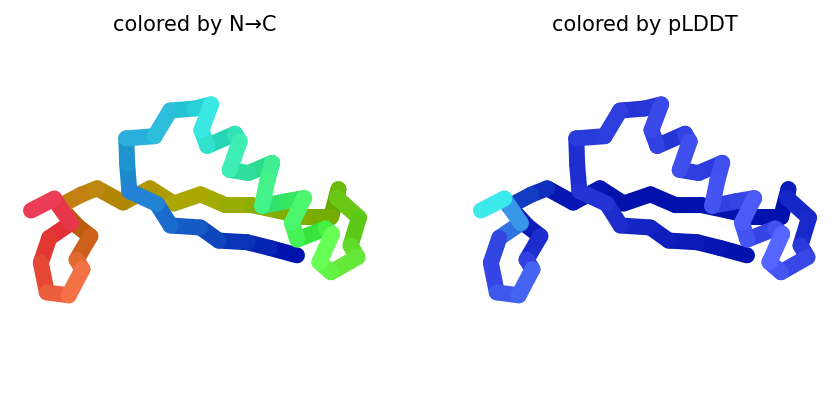

2026-11-03 13:08:47,398 alphafold2_ptm_model_2_seed_000 recycle=0 pLDDT=96.9 pTM=0.761
2026-11-03 13:08:51,022 alphafold2_ptm_model_2_seed_000 recycle=1 pLDDT=97 pTM=0.767 tol=0.311
2026-11-03 13:08:54,650 alphafold2_ptm_model_2_seed_000 recycle=2 pLDDT=96.8 pTM=0.763 tol=0.15
2026-11-03 13:08:58,283 alphafold2_ptm_model_2_seed_000 recycle=3 pLDDT=96.6 pTM=0.763 tol=0.0417
2026-11-03 13:08:58,285 alphafold2_ptm_model_2_seed_000 took 14.5s (3 recycles)


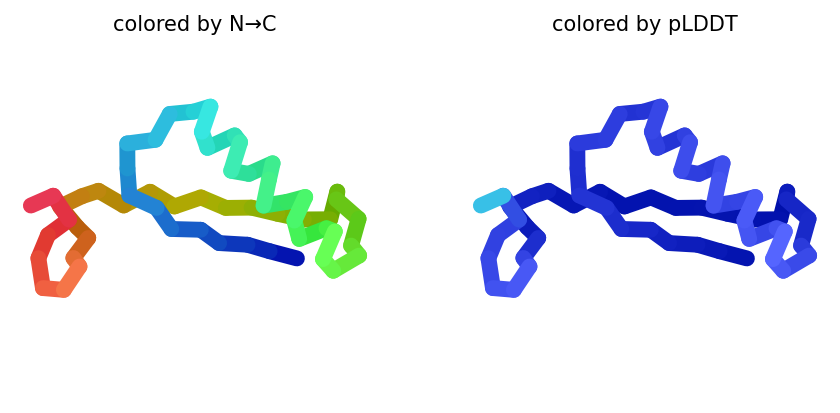

2026-11-03 13:09:02,007 alphafold2_ptm_model_3_seed_000 recycle=0 pLDDT=97.2 pTM=0.775
2026-11-03 13:09:05,624 alphafold2_ptm_model_3_seed_000 recycle=1 pLDDT=97.4 pTM=0.783 tol=0.232
2026-11-03 13:09:09,230 alphafold2_ptm_model_3_seed_000 recycle=2 pLDDT=97.4 pTM=0.782 tol=0.0975
2026-11-03 13:09:12,833 alphafold2_ptm_model_3_seed_000 recycle=3 pLDDT=97.4 pTM=0.782 tol=0.0534
2026-11-03 13:09:12,834 alphafold2_ptm_model_3_seed_000 took 14.5s (3 recycles)


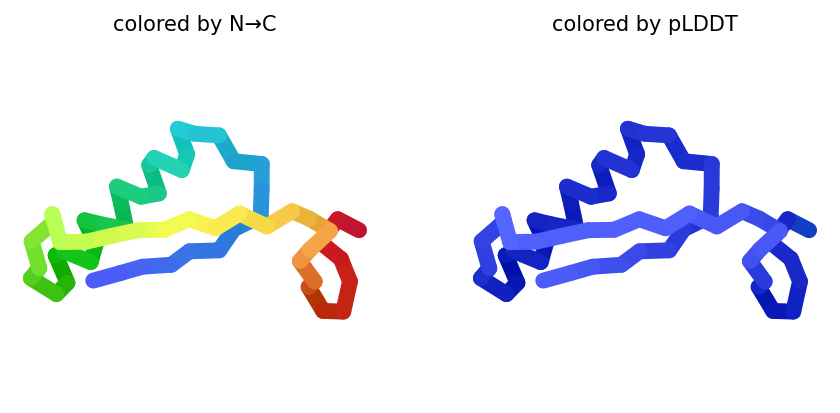

2026-11-03 13:09:16,519 alphafold2_ptm_model_4_seed_000 recycle=0 pLDDT=97.2 pTM=0.773
2026-11-03 13:09:20,108 alphafold2_ptm_model_4_seed_000 recycle=1 pLDDT=97.2 pTM=0.778 tol=0.229
2026-11-03 13:09:23,675 alphafold2_ptm_model_4_seed_000 recycle=2 pLDDT=97 pTM=0.777 tol=0.0703
2026-11-03 13:09:27,246 alphafold2_ptm_model_4_seed_000 recycle=3 pLDDT=96.7 pTM=0.775 tol=0.0651
2026-11-03 13:09:27,247 alphafold2_ptm_model_4_seed_000 took 14.3s (3 recycles)


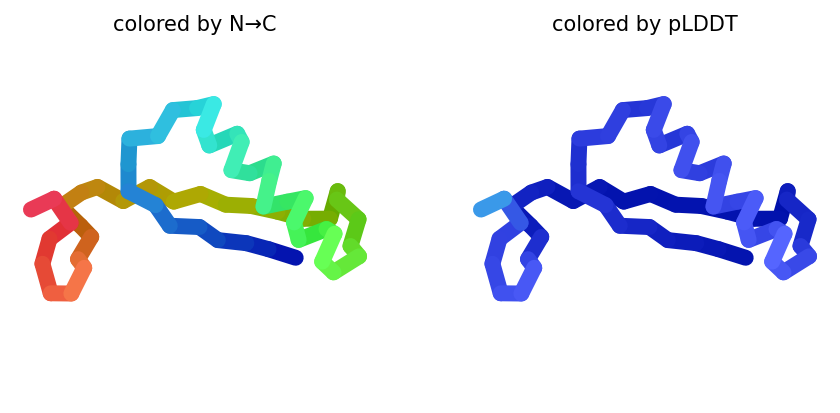

2026-11-03 13:09:30,951 alphafold2_ptm_model_5_seed_000 recycle=0 pLDDT=97 pTM=0.781
2026-11-03 13:09:34,521 alphafold2_ptm_model_5_seed_000 recycle=1 pLDDT=96.4 pTM=0.781 tol=0.277
2026-11-03 13:09:38,100 alphafold2_ptm_model_5_seed_000 recycle=2 pLDDT=96.3 pTM=0.778 tol=0.18
2026-11-03 13:09:41,672 alphafold2_ptm_model_5_seed_000 recycle=3 pLDDT=96.2 pTM=0.777 tol=0.0886
2026-11-03 13:09:41,673 alphafold2_ptm_model_5_seed_000 took 14.3s (3 recycles)


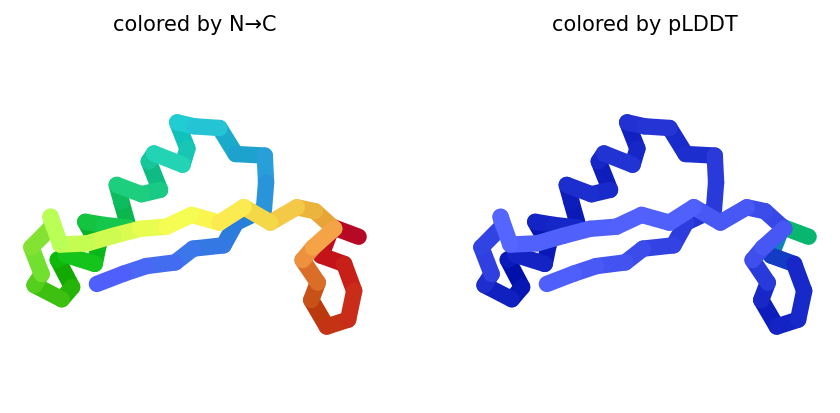

2026-11-03 13:09:41,802 reranking models by 'plddt' metric
2026-11-03 13:09:41,803 rank_001_alphafold2_ptm_model_3_seed_000 pLDDT=97.4 pTM=0.782
2026-11-03 13:09:41,803 rank_002_alphafold2_ptm_model_4_seed_000 pLDDT=96.7 pTM=0.775
2026-11-03 13:09:41,803 rank_003_alphafold2_ptm_model_2_seed_000 pLDDT=96.6 pTM=0.763
2026-11-03 13:09:41,805 rank_004_alphafold2_ptm_model_5_seed_000 pLDDT=96.2 pTM=0.777
2026-11-03 13:09:41,805 rank_005_alphafold2_ptm_model_1_seed_000 pLDDT=95.5 pTM=0.75
2026-11-03 13:09:43,161 Done


0

In [17]:
#@title Run Prediction
display_images = True #@param {type:"boolean"}

import sys
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
from Bio import BiopythonDeprecationWarning
warnings.simplefilter(action='ignore', category=BiopythonDeprecationWarning)
from pathlib import Path
from colabfold.download import download_alphafold_params, default_data_dir
from colabfold.utils import setup_logging
from colabfold.batch import get_queries, run, set_model_type
from colabfold.plot import plot_msa_v2

import os
import numpy as np
try:
  K80_chk = os.popen('nvidia-smi | grep "Tesla K80" | wc -l').read()
except:
  K80_chk = "0"
  pass
if "1" in K80_chk:
  print("WARNING: found GPU Tesla K80: limited to total length < 1000")
  if "TF_FORCE_UNIFIED_MEMORY" in os.environ:
    del os.environ["TF_FORCE_UNIFIED_MEMORY"]
  if "XLA_PYTHON_CLIENT_MEM_FRACTION" in os.environ:
    del os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]

from colabfold.colabfold import plot_protein
from pathlib import Path
import matplotlib.pyplot as plt

# Fallbacks seguros para variáveis que seriam criadas na primeira célula
if 'use_templates' not in globals():
  use_templates = False
if 'custom_template_path' not in globals():
  custom_template_path = None
if 'num_relax' not in globals():
  num_relax = 0

def input_features_callback(input_features):
  if display_images:
    plot_msa_v2(input_features)
    plt.show()
    plt.close()

def prediction_callback(protein_obj, length,
                        prediction_result, input_features, mode):
  model_name, relaxed = mode
  if not relaxed:
    if display_images:
      fig = plot_protein(protein_obj, Ls=length, dpi=150)
      plt.show()
      plt.close()

result_dir = jobname
log_filename = os.path.join(jobname,"log.txt")
setup_logging(Path(log_filename))

queries, is_complex = get_queries(queries_path)
model_type = set_model_type(is_complex, model_type)

if "multimer" in model_type and max_msa is not None:
  use_cluster_profile = False
else:
  use_cluster_profile = True

download_alphafold_params(model_type, Path("."))
results = run(
    queries=queries,
    result_dir=result_dir,
    use_templates=use_templates,
    custom_template_path=custom_template_path,
    num_relax=num_relax,
    msa_mode=msa_mode,
    model_type=model_type,
    num_models=5,
    num_recycles=num_recycles,
    relax_max_iterations=relax_max_iterations,
    recycle_early_stop_tolerance=recycle_early_stop_tolerance,
    num_seeds=num_seeds,
    use_dropout=use_dropout,
    use_fast_kernels=use_fast_kernels,
    model_order=[1,2,3,4,5],
    is_complex=is_complex,
    data_dir=Path("."),
    keep_existing_results=False,
    rank_by="auto",
    pair_mode=pair_mode,
    pairing_strategy=pairing_strategy,
    stop_at_score=float(100),
    prediction_callback=prediction_callback,
    dpi=dpi,
    zip_results=False,
    save_all=save_all,
    max_msa=max_msa,
    use_cluster_profile=use_cluster_profile,
    input_features_callback=input_features_callback,
    save_recycles=save_recycles,
    user_agent="colabfold/google-colab-main",
    calc_extra_ptm=calc_extra_ptm,
)
results_zip = f"{jobname}.result.zip"
os.system(f"zip -r {results_zip} {jobname}")

In [7]:
#@title Display 3D structure {run: "auto"}
import py3Dmol
import glob
import matplotlib.pyplot as plt
from colabfold.colabfold import plot_plddt_legend
from colabfold.colabfold import pymol_color_list, alphabet_list
rank_num = 1 #@param ["1", "2", "3", "4", "5"] {type:"raw"}
color = "lDDT" #@param ["chain", "lDDT", "rainbow"]
show_sidechains = False #@param {type:"boolean"}
show_mainchains = False #@param {type:"boolean"}

tag = results["rank"][0][rank_num - 1]
jobname_prefix = ".custom" if msa_mode == "custom" else ""
pdb_filename = f"{jobname}/{jobname}{jobname_prefix}_unrelaxed_{tag}.pdb"
pdb_file = glob.glob(pdb_filename)

def show_pdb(rank_num=1, show_sidechains=False, show_mainchains=False, color="lDDT"):
  model_name = f"rank_{rank_num}"
  view = py3Dmol.view(js='https://3dmol.org/build/3Dmol.js',)
  view.addModel(open(pdb_file[0],'r').read(),'pdb')

  if color == "lDDT":
    view.setStyle({'cartoon': {'colorscheme': {'prop':'b','gradient': 'roygb','min':50,'max':90}}})
  elif color == "rainbow":
    view.setStyle({'cartoon': {'color':'spectrum'}})
  elif color == "chain":
    chains = len(queries[0][1]) + 1 if is_complex else 1
    for n,chain,color in zip(range(chains),alphabet_list,pymol_color_list):
       view.setStyle({'chain':chain},{'cartoon': {'color':color}})

  if show_sidechains:
    BB = ['C','O','N']
    view.addStyle({'and':[{'resn':["GLY","PRO"],'invert':True},{'atom':BB,'invert':True}]},
                        {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"GLY"},{'atom':'CA'}]},
                        {'sphere':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"PRO"},{'atom':['C','O'],'invert':True}]},
                        {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
  if show_mainchains:
    BB = ['C','O','N','CA']
    view.addStyle({'atom':BB},{'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})

  view.zoomTo()
  return view

show_pdb(rank_num, show_sidechains, show_mainchains, color).show()
if color == "lDDT":
  plot_plddt_legend().show()

ModuleNotFoundError: No module named 'py3Dmol'

In [ ]:
#@title Plots {run: "auto"}
from IPython.display import display, HTML
import base64
from html import escape

# see: https://stackoverflow.com/a/53688522
def image_to_data_url(filename):
  ext = filename.split('.')[-1]
  prefix = f'data:image/{ext};base64,'
  with open(filename, 'rb') as f:
    img = f.read()
  return prefix + base64.b64encode(img).decode('utf-8')

pae = ""
pae_file = os.path.join(jobname,f"{jobname}{jobname_prefix}_pae.png")
if os.path.isfile(pae_file):
    pae = image_to_data_url(pae_file)
cov = image_to_data_url(os.path.join(jobname,f"{jobname}{jobname_prefix}_coverage.png"))
plddt = image_to_data_url(os.path.join(jobname,f"{jobname}{jobname_prefix}_plddt.png"))
display(HTML(f"""
<style>
  img {{
    float:left;
  }}
  .full {{
    max-width:100%;
  }}
  .half {{
    max-width:50%;
  }}
  @media (max-width:640px) {{
    .half {{
      max-width:100%;
    }}
  }}
</style>
<div style="max-width:90%; padding:2em;">
  <h1>Plots for {escape(jobname)}</h1>
  { '<!--' if pae == '' else '' }<img src="{pae}" class="full" />{ '-->' if pae == '' else '' }
  <img src="{cov}" class="half" />
  <img src="{plddt}" class="half" />
</div>
"""))

In [18]:
#@title Package and download results
#@markdown If you are having issues downloading the result archive, try disabling your adblocker and run this cell again. If that fails click on the little folder icon to the left, navigate to file: `jobname.result.zip`, right-click and select \"Download\" (see [screenshot](https://pbs.twimg.com/media/E6wRW2lWUAEOuoe?format=jpg&name=small)).

if msa_mode == "custom":
  print("Don't forget to cite your custom MSA generation method.")

files.download(f"{jobname}.result.zip")

if save_to_google_drive == True and drive:
  uploaded = drive.CreateFile({'title': f"{jobname}.result.zip"})
  uploaded.SetContentFile(f"{jobname}.result.zip")
  uploaded.Upload()
  print(f"Uploaded {jobname}.result.zip to Google Drive with ID {uploaded.get('id')}")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Instructions <a name="Instructions"></a>
For detailed instructions, tips and tricks, see recently published paper at [Nature Protocols](https://www.nature.com/articles/s41596-024-01060-5)

**Quick start**
1. Paste your protein sequence(s) in the input field.
2. Press "Runtime" -> "Run all".
3. The pipeline consists of 5 steps. The currently running step is indicated by a circle with a stop sign next to it.

**Result zip file contents**

1. PDB formatted structures sorted by avg. pLDDT and complexes are sorted by pTMscore. (unrelaxed and relaxed if `use_amber` is enabled).
2. Plots of the model quality.
3. Plots of the MSA coverage.
4. Parameter log file.
5. A3M formatted input MSA.
6. A `predicted_aligned_error_v1.json` using [AlphaFold-DB's format](https://alphafold.ebi.ac.uk/faq#faq-7) and a `scores.json` for each model which contains an array (list of lists) for PAE, a list with the average pLDDT and the pTMscore.
7. BibTeX file with citations for all used tools and databases.

At the end of the job a download modal box will pop up with a `jobname.result.zip` file. Additionally, if the `save_to_google_drive` option was selected, the `jobname.result.zip` will be uploaded to your Google Drive.

**MSA generation for complexes**

For the complex prediction we use unpaired and paired MSAs. Unpaired MSA is generated the same way as for the protein structures prediction by searching the UniRef100 and environmental sequences three iterations each.

The paired MSA is generated by searching the UniRef100 database and pairing the best hits sharing the same NCBI taxonomic identifier (=species or sub-species). We only pair sequences if all of the query sequences are present for the respective taxonomic identifier.

**Using a custom MSA as input**

To predict the structure with a custom MSA (A3M formatted): (1) Change the `msa_mode`: to "custom", (2) Wait for an upload box to appear at the end of the "MSA options ..." box. Upload your A3M. The first fasta entry of the A3M must be the query sequence without gaps.

It is also possilbe to provide custom MSAs for complex predictions. Read more about the format [here](https://github.com/sokrypton/ColabFold/issues/76).

As an alternative for MSA generation the [HHblits Toolkit server](https://toolkit.tuebingen.mpg.de/tools/hhblits) can be used. After submitting your query, click "Query Template MSA" -> "Download Full A3M". Download the A3M file and upload it in this notebook.

**PDB100** <a name="pdb100"></a>

As of 23/06/08, we have transitioned from using the PDB70 to a 100% clustered PDB, the PDB100. The construction methodology of PDB100 differs from that of PDB70.

The PDB70 was constructed by running each PDB70 representative sequence through [HHblits](https://github.com/soedinglab/hh-suite) against the [Uniclust30](https://uniclust.mmseqs.com/). On the other hand, the PDB100 is built by searching each PDB100 representative structure with [Foldseek](https://github.com/steineggerlab/foldseek) against the [AlphaFold Database](https://alphafold.ebi.ac.uk).

To maintain compatibility with older Notebook versions and local installations, the generated files and API responses will continue to be named "PDB70", even though we're now using the PDB100.

**Using custom templates** <a name="custom_templates"></a>

To predict the structure with a custom template (PDB or mmCIF formatted): (1) change the `template_mode` to "custom" in the execute cell and (2) wait for an upload box to appear at the end of the "Input Protein" box. Select and upload your templates (multiple choices are possible).

* Templates must follow the four letter PDB naming with lower case letters.

* Templates in mmCIF format must contain `_entity_poly_seq`. An error is thrown if this field is not present. The field `_pdbx_audit_revision_history.revision_date` is automatically generated if it is not present.

* Templates in PDB format are automatically converted to the mmCIF format. `_entity_poly_seq` and `_pdbx_audit_revision_history.revision_date` are automatically generated.

If you encounter problems, please report them to this [issue](https://github.com/sokrypton/ColabFold/issues/177).

**Comparison to the full AlphaFold2 and AlphaFold2 Colab**

This notebook replaces the homology detection and MSA pairing of AlphaFold2 with MMseqs2. For a comparison against the [AlphaFold2 Colab](https://colab.research.google.com/github/deepmind/alphafold/blob/main/notebooks/AlphaFold.ipynb) and the full [AlphaFold2](https://github.com/deepmind/alphafold) system read our [paper](https://www.nature.com/articles/s41592-022-01488-1).

**Troubleshooting**
* Check that the runtime type is set to GPU at "Runtime" -> "Change runtime type".
* Try to restart the session "Runtime" -> "Factory reset runtime".
* Check your input sequence.

**Known issues**
* Google Colab assigns different types of GPUs with varying amount of memory. Some might not have enough memory to predict the structure for a long sequence.
* Your browser can block the pop-up for downloading the result file. You can choose the `save_to_google_drive` option to upload to Google Drive instead or manually download the result file: Click on the little folder icon to the left, navigate to file: `jobname.result.zip`, right-click and select \"Download\" (see [screenshot](https://pbs.twimg.com/media/E6wRW2lWUAEOuoe?format=jpg&name=small)).

**Limitations**
* Computing resources: Our MMseqs2 API can handle ~20-50k requests per day.
* MSAs: MMseqs2 is very precise and sensitive but might find less hits compared to HHblits/HMMer searched against BFD or MGnify.
* We recommend to additionally use the full [AlphaFold2 pipeline](https://github.com/deepmind/alphafold).

**Description of the plots**
*   **Number of sequences per position** - We want to see at least 30 sequences per position, for best performance, ideally 100 sequences.
*   **Predicted lDDT per position** - model confidence (out of 100) at each position. The higher the better.
*   **Predicted Alignment Error** - For homooligomers, this could be a useful metric to assess how confident the model is about the interface. The lower the better.

**Bugs**
- If you encounter any bugs, please report the issue to https://github.com/sokrypton/ColabFold/issues

**License**

The source code of ColabFold is licensed under [MIT](https://raw.githubusercontent.com/sokrypton/ColabFold/main/LICENSE). Additionally, this notebook uses the AlphaFold2 source code and its parameters licensed under [Apache 2.0](https://raw.githubusercontent.com/deepmind/alphafold/main/LICENSE) and [CC BY 4.0](https://creativecommons.org/licenses/by-sa/4.0/) respectively. Read more about the AlphaFold license [here](https://github.com/deepmind/alphafold).

**Acknowledgments**
- We thank the AlphaFold team for developing an excellent model and open sourcing the software.

- [KOBIC](https://kobic.re.kr) and [Söding Lab](https://www.mpinat.mpg.de/soeding) for providing the computational resources for the MMseqs2 MSA server.

- Richard Evans for helping to benchmark the ColabFold's Alphafold-multimer support.

- [David Koes](https://github.com/dkoes) for his awesome [py3Dmol](https://3dmol.csb.pitt.edu/) plugin, without whom these notebooks would be quite boring!

- Do-Yoon Kim for creating the ColabFold logo.

- A colab by Sergey Ovchinnikov ([@sokrypton](https://twitter.com/sokrypton)), Milot Mirdita ([@milot_mirdita](https://twitter.com/milot_mirdita)) and Martin Steinegger ([@thesteinegger](https://twitter.com/thesteinegger)).
